# Kompletny przewodnik: NumPy (od podstaw po analizy i ML)

Przewodnik referencyjny (Python 3.10+, NumPy 2.x; testowany na 2.5). Prowadzi od podstaw (`ndarray`, indeksowanie, broadcasting) przez funkcje szczególnie przydatne w analizie danych, a często **bez dobrego odpowiednika w pandas/Polars** (`where`, `select`, `logical_*`, `quantile`, `clip`, `maximum`, `digitize`, `argpartition`, `interp`, `ptp`…), po algebrę liniową, losowość, szeregi czasowe i implementacje algorytmów ML „od zera".

Każda sekcja zaczyna się od **wersji podstawowej** (kilka linii), potem są tabele parametrów (✅ = wymagany, ⬜ = opcjonalny) i rozszerzenia. Kod jest „inline"; funkcja pojawia się tylko tam, gdzie wzorzec jest realnie wielokrotnego użytku (zaznaczone w tekście). Każda komórka jest samodzielna po wykonaniu sekcji **0**.

**Spis treści**

0. Setup, dane przykładowe, zmiany w NumPy 2.x
1. `ndarray`: tworzenie, typy (`dtype`), atrybuty
2. Indeksowanie: slicing, maski, indeksowanie fancy, widoki vs kopie
3. Kształty i łączenie tablic
4. Broadcasting i ufunc
5. Agregacje, statystyka, sortowanie, zbiory
6. **Funkcje, które w analizie robią różnicę** (`where`, `select`, `logical_*`, `quantile`, `clip`, `maximum`, `digitize`, `argpartition`, `interp`, `ptp` i inne)
7. Algebra liniowa (`@`, `einsum`, `solve`, `lstsq`, `svd`, `eigh`)
8. Losowość: `Generator`, próbkowanie, bootstrap, testy permutacyjne
9. Szeregi czasowe i okna kroczące; daty (`datetime64`)
10. NumPy w ML: implementacje od zera i weryfikacja z scikit-learn
11. Wydajność i pamięć
12. Braki danych i tablice maskowane
13. Współpraca z pandas, Polars, scikit-learn
14. Zmiany w NumPy 2.x i typowe pułapki
15. Ściągawka: zadanie → funkcja; NumPy vs pandas vs Polars

## 0. Setup i dane przykładowe

In [132]:
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", rc={"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
np.set_printoptions(precision=3, suppress=True, linewidth=110, legacy="1.25")   # czytelniejszy wydruk (legacy: skalary bez przedrostka np.float64(...))
print(np.__version__, pd.__version__, pl.__version__)

2.2.3 3.0.6 1.41.2


### Dane przykładowe

Tablice NumPy opisujące 1000 zamówień (jednolite typy w każdej tablicy), macierz cech `X` i etykiety `y` do ML oraz szereg czasowy.

In [133]:
rng = np.random.default_rng(42)                      # nowoczesny generator liczb losowych (zob. sekcja 8)
n = 1000

age = np.clip(rng.normal(40, 12, n), 18, 80).round().astype(np.int64)        # int
income = rng.lognormal(8.2, 0.5, n).round(0)                                 # float, skośny
units = rng.poisson(3, n) + 1                                                # int (licznik)
unit_price = rng.gamma(6, 12, n).round(2)                                    # float
discount = np.clip(rng.beta(2, 12, n), 0, 0.5).round(3)                      # float 0–0.5
revenue = (units * unit_price * (1 - discount)).round(2)                     # float, skośny
delivery_days = rng.gamma(3, 1.2, n).round(1)                                # float
delivery_days[rng.choice(n, 50, replace=False)] = np.nan                     # braki danych
satisfaction = rng.integers(1, 6, n)                                         # int 1–5
is_returning = rng.random(n) < 0.4                                           # bool
region = rng.choice(np.array(["Północ", "Południe", "Wschód", "Zachód", "Centrum"]), n)     # tekst (dtype <U8)
order_date = np.datetime64("2023-01-01") + rng.integers(0, 730, n).astype("timedelta64[D]") # datetime64[D]

# macierz cech i etykiety (ML): 5 cech, y zależy od cech + szum
X = np.column_stack([age, np.log(income), units, discount, np.nan_to_num(delivery_days, nan=np.nanmedian(delivery_days))]).astype(float)
y = (rng.random(n) < 1 / (1 + np.exp(-(0.8 * (X[:, 4] - X[:, 4].mean()) - 6 * (X[:, 3] - X[:, 3].mean()) - 0.6 * (X[:, 1] - X[:, 1].mean()))))).astype(int)
feature_names = ["age", "log_income", "units", "discount", "delivery_days"]

# szereg dzienny: trend + sezonowość tygodniowa + szum
t = np.arange(730)
ts = 100 + 0.05 * t + 8 * np.sin(2 * np.pi * t / 7) + rng.normal(0, 3, t.size)
ts[[120, 350, 610]] += np.array([28.0, -30.0, 32.0])                         # 3 wstrzyknięte anomalie (do sekcji 9)

print(X.shape, y.mean().round(3), ts.shape)

(1000, 5) 0.481 (730,)


### Co zmieniło się w NumPy 2.x (krótko, szczegóły w sekcji 14)

| Było | Jest |
|---|---|
| `np.float_`, `np.NaN`, `np.Inf`, `np.product`, `np.cumproduct`, `np.alltrue`, `np.round_` | `np.float64`, `np.nan`, `np.inf`, `np.prod`, `np.cumprod`, `np.all`, `np.round` (usunięte) |
| `np.in1d`, `np.trapz`, `np.row_stack` | `np.isin`, `np.trapezoid`, `np.vstack` (usunięte w 2.4–2.5) |
| `arr.ptp()` (metoda) | `np.ptp(arr)` (metoda usunięta w 2.0) |
| `np.fix` | `np.trunc` (`np.fix` przestarzałe w 2.5) |
| `np.cross` dla wektorów 2D | tylko wektory 3D (2D usunięte w 2.5) |

## 1. `ndarray`: tworzenie, typy, atrybuty

**`ndarray`** to jednorodna (jeden `dtype`), ciągła w pamięci tablica N-wymiarowa. Operacje na całej tablicy są wykonywane w skompilowanym kodzie C, czyli dziesiątki–setki razy szybciej niż pętle Pythona.

#### Wersja podstawowa

In [134]:
a = np.array([1, 2, 3, 4])                   # z listy
b = np.array([[1, 2, 3], [4, 5, 6]])         # macierz 2×3
print(a.shape, a.dtype, b.shape, b.ndim, b.size)

a * 2, a + a, a ** 2, a > 2                  # operacje elementowe (bez pętli)

(4,) int64 (2, 3) 2 6


(array([2, 4, 6, 8]),
 array([2, 4, 6, 8]),
 array([ 1,  4,  9, 16]),
 array([False, False,  True,  True]))

### 1.1. Atrybuty

| Atrybut | Znaczenie |
|---|---|
| `a.shape` | Krotka wymiarów, np. `(1000, 5)` |
| `a.ndim` | Liczba osi |
| `a.size` | Liczba elementów |
| `a.dtype` | Typ elementów (`int64`, `float64`, `bool`, `<U8`, `datetime64[D]`) |
| `a.itemsize`, `a.nbytes` | Bajty na element / razem |
| `a.strides` | Krok w bajtach w każdej osi (jak układ w pamięci) |
| `a.flags` | `C_CONTIGUOUS`, `F_CONTIGUOUS`, `OWNDATA`, `WRITEABLE` |
| `a.T` | Transpozycja (widok) |
| `a.base` | Tablica, której widokiem jest `a` (`None` = własne dane) |

In [135]:
print(X.shape, X.ndim, X.size, X.dtype, X.itemsize, X.nbytes, X.strides, X.flags["C_CONTIGUOUS"])

(1000, 5) 2 5000 float64 8 40000 (40, 8) True


### 1.2. Tworzenie tablic

| Funkcja | Parametry (✅ wymagane / ⬜ opcjonalne) | Przykład |
|---|---|---|
| `np.array(obj)` | ✅ `obj`; ⬜ `dtype`, `copy`, `ndmin`, `order` | `np.array([1, 2], dtype=float)` |
| `np.zeros(shape)` / `np.ones(shape)` | ✅ `shape`; ⬜ `dtype` | `np.zeros((3, 4))` |
| `np.full(shape, fill_value)` | ✅ oba; ⬜ `dtype` | `np.full((2, 2), np.nan)` |
| `np.empty(shape)` | ✅ `shape` (zawartość niezainicjalizowana!) | szybki bufor do nadpisania |
| `np.arange(start, stop, step)` | ✅ `stop`; ⬜ `start`, `step`, `dtype` | `np.arange(0, 10, 2)` |
| `np.linspace(start, stop, num)` | ✅ `start`, `stop`; ⬜ `num` (50), `endpoint`, `retstep` | `np.linspace(0, 1, 5)` |
| `np.logspace(start, stop, num)` | wykładniki (domyślnie baza 10) | `np.logspace(0, 3, 4)` |
| `np.eye(N)` / `np.identity(N)` | macierz jednostkowa | `np.eye(3)` |
| `np.diag(v)` | ✅ `v`: wektor → macierz diagonalna, macierz → jej przekątna | `np.diag([1, 2, 3])` |
| `np.zeros_like(a)`, `np.ones_like`, `np.full_like`, `np.empty_like` | tablica o kształcie i typie jak `a` | `np.zeros_like(X)` |
| `np.fromfunction(f, shape)` | wartości z funkcji indeksów | tabliczka mnożenia |
| `np.meshgrid`, `np.mgrid`, `np.ogrid` | siatki współrzędnych (sekcja 3) | |
| `rng.random`, `rng.normal`, `rng.integers` | losowe (sekcja 8) | |

In [136]:
print(np.arange(0, 10, 2), np.linspace(0, 1, 5), np.logspace(0, 3, 4), sep="\n")      # arange: krok; linspace: liczba punktów (uwaga na floaty)
print(np.full((2, 3), np.nan), np.eye(3), np.diag([1, 2, 3]), sep="\n")
print(np.fromfunction(lambda i, j: (i + 1) * (j + 1), (4, 4), dtype=int))              # tabliczka mnożenia 4×4

[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[   1.   10.  100. 1000.]
[[nan nan nan]
 [nan nan nan]]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[[1 0 0]
 [0 2 0]
 [0 0 3]]
[[ 1  2  3  4]
 [ 2  4  6  8]
 [ 3  6  9 12]
 [ 4  8 12 16]]


### 1.3. Typy danych (`dtype`) i konwersje

| Rodzina | Typy | Uwagi |
|---|---|---|
| Całkowite | `int8/16/32/64`, `uint8/16/32/64` | Przepełnienie **bez ostrzeżenia** (`np.int8(127) + 1` zawija się) |
| Zmiennoprzecinkowe | `float16/32/64` | `float64` domyślne; `float32` oszczędza pamięć (ML/GPU) |
| Logiczne | `bool` | `np.bool` (alias `np.bool_`) |
| Tekst | `<U8` (Unicode o stałej długości), `StringDType` (NumPy 2: zmienna długość) | Tablice tekstowe są wolne; do tekstu lepsze pandas/Polars |
| Czas | `datetime64[D/h/s…]`, `timedelta64` | Sekcja 9 |
| Obiektowe | `object` | Wolne; unikaj |

In [137]:
a = np.array([1, 2, 3])                                      # int64
print(a.astype(np.float32), a.astype(bool), np.array([1.7, -1.7]).astype(int))   # astype: kopia; float → int ucina (trunc), nie zaokrągla
print(np.array([1, 2.5, True]).dtype, np.array(["a", 1]).dtype)                   # podwyższanie typu: int<float<complex; mieszanie z tekstem → tekst
print(np.iinfo(np.int8), np.finfo(np.float32).eps)                                # zakresy typów, precyzja

with np.errstate(over="ignore"):                             # przepełnienie całkowite: ciche zawijanie
    print(np.int8(127) + np.int8(1))
print(np.result_type(np.int32, np.float32), np.can_cast(np.float64, np.float32))  # reguły promocji typów

[1. 2. 3.] [ True  True  True] [ 1 -1]
float64 <U21
Machine parameters for int8
---------------------------------------------------------------
min = -128
max = 127
---------------------------------------------------------------
 1.1920929e-07
-128
float64 False


## 2. Indeksowanie: slicing, maski, indeksowanie fancy

#### Wersja podstawowa

In [138]:
a = np.arange(10)                     # [0 1 2 ... 9]
print(a[0], a[-1], a[2:5], a[::2], a[::-1])  # element, ostatni, wycinek, co drugi, odwrócona

m = np.arange(12).reshape(3, 4)
print(m[1, 2], m[1], m[:, 0], m[0:2, 1:3])   # element, wiersz, kolumna, podmacierz
a[a > 6]                              # maska logiczna: elementy spełniające warunek

0 9 [2 3 4] [0 2 4 6 8] [9 8 7 6 5 4 3 2 1 0]
6 [4 5 6 7] [0 4 8] [[1 2]
 [5 6]]


array([7, 8, 9])

### 2.1. Rodzaje indeksowania

| Rodzaj | Składnia | Wynik | Widok czy kopia? |
|---|---|---|---|
| Podstawowy (slicing) | `a[2:8:2]`, `m[:, 1]`, `m[..., 0]` | tablica | **widok** (zmiana w widoku zmienia oryginał) |
| `newaxis` | `a[:, np.newaxis]` (lub `a[:, None]`) | dodaje oś | widok |
| Maska logiczna | `a[a > 0]`, `m[mask_rows]` | tablica 1D (dla pełnej maski) | **kopia** |
| Fancy (lista indeksów) | `a[[1, 3, 5]]`, `m[[0, 2], :]` | tablica | **kopia** |
| Fancy 2D (pary) | `m[[0, 1], [2, 3]]` → `m[0,2]`, `m[1,3]` | tablica 1D | kopia |
| Siatka indeksów | `m[np.ix_([0, 2], [1, 3])]` | podmacierz (iloczyn) | kopia |

In [139]:
m = np.arange(12).reshape(3, 4)
print(m[[0, 2], [1, 3]], m[np.ix_([0, 2], [1, 3])], sep="\n")             # pary (0,1),(2,3) vs podmacierz wierszy 0,2 × kolumn 1,3
print(m[..., -1], m[:, None, 0].shape)                                     # Ellipsis (...) i newaxis

# przypisania przez indeksy
b = np.zeros(8, dtype=int)
b[2:5] = 9;  b[[0, 7]] = -1;  b[b == 0] = 5
print(b)

# funkcje indeksujące
v = np.array([5, 0, 8, 0, 3])
print(np.nonzero(v), np.flatnonzero(v), np.argwhere(v == 0).ravel(), sep=" | ")     # gdzie != 0 / gdzie == 0
print(np.take(v, [0, 2, 4]), np.compress(v > 2, v), np.extract(v > 2, v))           # take = fancy; compress/extract = maska
np.put(v, [0, 1], [100, 200]); print(v)                                              # put: zapis przez indeksy

[ 1 11]
[[ 1  3]
 [ 9 11]]
[ 3  7 11] (3, 1)
[-1  5  9  9  9  5  5 -1]
(array([0, 2, 4]),) | [0 2 4] | [1 3]
[5 8 3] [5 8 3] [5 8 3]
[100 200   8   0   3]


### 2.2. Widoki i kopie: najważniejsza pułapka wydajności i poprawności

In [140]:
a = np.arange(6)
view = a[1:4]                        # widok: wspólna pamięć
view[0] = 99
print(a)                             # a się zmieniło!
copy = a[1:4].copy()                 # jawna kopia
copy[0] = -1
print(a, np.shares_memory(a, view), np.shares_memory(a, copy), view.base is a)

# maska/fancy zawsze tworzą KOPIĘ, więc łańcuchowe przypisanie nie zadziała:
b = np.array([1, -2, 3, -4])
b[b < 0][0] = 0                      # modyfikuje kopię! b bez zmian
print(b)
b[np.flatnonzero(b < 0)[0]] = 0      # poprawnie: jedno przypisanie przez indeks
print(b)

[ 0 99  2  3  4  5]
[ 0 99  2  3  4  5] True False True
[ 1 -2  3 -4]
[ 1  0  3 -4]


### 2.3. Maski w analizie: łączenie warunków

Przy łączeniu warunków używaj `&` (i), `|` (lub), `~` (nie), **zawsze z nawiasami** (priorytet operatorów). Słów `and`/`or` użyć nie można (błąd „truth value of an array is ambiguous"). Pełna lista funkcji logicznych jest w sekcji 6.2.

In [141]:
mask = (income > 5000) & (discount < 0.1) & ~is_returning          # i, i, nie
print(mask.sum(), mask.mean().round(3), revenue[mask].mean().round(1))      # liczba, udział, średnia w podzbiorze
print(region[(revenue > np.quantile(revenue, 0.95))][:5])                    # indeksowanie maską innej tablicy tej samej długości

# indeksy najlepszych: argsort + slicing
top5 = np.argsort(revenue)[::-1][:5]
print(top5, revenue[top5])

50 0.05 262.1
['Zachód' 'Centrum' 'Centrum' 'Zachód' 'Zachód']
[757 106 574 427 376] [1111.69  906.06  875.68  845.2   795.57]


## 3. Kształty i łączenie tablic

#### Wersja podstawowa

In [142]:
a = np.arange(12)
print(a.reshape(3, 4))                 # zmiana kształtu (liczba elementów musi się zgadzać)
print(a.reshape(3, -1))                # -1: NumPy wylicza wymiar
print(a.reshape(3, 4).T)               # transpozycja
np.concatenate([a[:3], a[3:6]]) # sklejanie

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[ 0  4  8]
 [ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]]


array([0, 1, 2, 3, 4, 5])

| Operacja | Funkcja | Uwagi |
|---|---|---|
| Zmiana kształtu | `a.reshape(shape)` ✅ | Zwraca widok, gdy możliwe; `-1` = automatycznie |
| Spłaszczenie | `a.ravel()` (widok jeśli się da), `a.flatten()` (zawsze kopia) | |
| Transpozycja / zamiana osi | `a.T`, `np.transpose(a, axes)`, `np.swapaxes(a, 0, 1)`, `np.moveaxis(a, src, dst)` | Widoki |
| Dodanie / usunięcie osi | `a[:, None]`, `np.expand_dims(a, axis)`, `np.squeeze(a, axis)` | Wektor kolumnowy `(n, 1)` vs `(n,)` |
| Sklejanie | `np.concatenate([a, b], axis=0)`, `np.vstack`, `np.hstack`, `np.dstack`, `np.column_stack` | Wymiary poza `axis` muszą się zgadzać |
| Nowa oś przy sklejaniu | `np.stack([a, b], axis=0)` | Wszystkie tablice tego samego kształtu |
| Dzielenie | `np.split(a, k)` (równo), `np.array_split(a, k)` (nierówno), `np.hsplit`, `np.vsplit` | `k` lub lista indeksów |
| Powielanie | `np.tile(a, reps)` (cały blok), `np.repeat(a, reps, axis)` (element po elemencie) | |
| Odwracanie, przesuwanie | `np.flip(a, axis)`, `np.roll(a, shift, axis)`, `np.rot90` | `roll`: cyklicznie (np. lag z zawinięciem) |
| Dopełnienie | `np.pad(a, pad_width, mode)` | `mode`: `"constant"`, `"edge"`, `"reflect"`, `"wrap"` |
| Skrócone konstruktory | `np.r_[a, b]`, `np.c_[a, b]` | Szybkie sklejanie wierszowe/kolumnowe |
| Siatki | `np.meshgrid(x, y)`, `np.mgrid[0:3, 0:4]`, `np.ogrid` | Współrzędne dla map, powierzchni, macierzy odległości |
| Wymuszenie wymiarów | `np.atleast_1d/2d/3d` | Ujednolicenie wejść funkcji |

In [143]:
a = np.arange(6)
print(a.reshape(2, 3), a.reshape(3, -1), a.reshape(2, 3).ravel(), sep="\n")
x, y2 = np.arange(3), np.arange(3, 6)
print(np.concatenate([x, y2]), np.vstack([x, y2]), np.hstack([x, y2]), np.column_stack([x, y2]), np.stack([x, y2], axis=1), sep="\n")
print(np.split(np.arange(9), 3), np.array_split(np.arange(10), 3), sep="\n")           # array_split pozwala na nierówny podział
print(np.tile([1, 2], 3), np.repeat([1, 2], 3), np.roll(np.arange(5), 2), np.pad([1, 2, 3], (2, 1), constant_values=0))
print(np.r_[1:4, 10, 20], np.c_[[1, 2], [3, 4]], sep="\n")

# siatka współrzędnych: wartość funkcji dwóch zmiennych
gx, gy = np.meshgrid(np.linspace(-2, 2, 5), np.linspace(-1, 1, 3))                       # indexing="xy" (domyślnie)
print(gx.shape, (gx ** 2 + gy ** 2).round(2))

# (n,) vs (n,1): częsta przyczyna błędów broadcastingu
v = np.arange(3)
print(v.shape, v[:, None].shape, (v[:, None] + v).shape)                                  # (3,) + (3,1)→(3,3)

[[0 1 2]
 [3 4 5]]
[[0 1]
 [2 3]
 [4 5]]
[0 1 2 3 4 5]
[0 1 2 3 4 5]
[[0 1 2]
 [3 4 5]]
[0 1 2 3 4 5]
[[0 3]
 [1 4]
 [2 5]]
[[0 3]
 [1 4]
 [2 5]]
[array([0, 1, 2]), array([3, 4, 5]), array([6, 7, 8])]
[array([0, 1, 2, 3]), array([4, 5, 6]), array([7, 8, 9])]
[1 2 1 2 1 2] [1 1 1 2 2 2] [3 4 0 1 2] [0 0 1 2 3 0]
[ 1  2  3 10 20]
[[1 3]
 [2 4]]
(3, 5) [[5. 2. 1. 2. 5.]
 [4. 1. 0. 1. 4.]
 [5. 2. 1. 2. 5.]]
(3,) (3, 1) (3, 3)


## 4. Broadcasting i ufunc

### 4.1. Broadcasting: reguły

Operacje na tablicach o **różnych kształtach** są możliwe, gdy porównując kształty **od prawej strony**, każda para wymiarów jest **równa albo jedna z nich to 1** (brakujące wymiary po lewej traktowane jak 1). Wymiar 1 jest „rozciągany" bez kopiowania danych.

```
 X:  (1000, 5)           X:  (1000, 5)         a:  (3, 1)
 m:       (5,)    ✓      s:  (1000, 1)   ✓     b:  (1, 4)     ✓ → (3, 4)
 → (1000, 5)             → (1000, 5)           c:  (3,)  vs (4,)  ✗ błąd
```

#### Wersja podstawowa

In [144]:
X[:5] - X.mean(axis=0)                  # (5, 5) − (5,): odjęcie średniej każdej kolumny od każdego wiersza

array([[  4.163,   0.011,  -2.919,   0.077,   8.982],
       [-11.837,  -0.324,  -0.919,   0.149,  -0.518],
       [  9.163,  -0.167,  -0.919,  -0.014,   3.582],
       [ 11.163,   0.358,   2.081,   0.175,   0.482],
       [-21.837,   0.042,  -1.919,  -0.104,  -0.818]])

In [145]:
# standaryzacja z-score kolumn (jak StandardScaler) i min-max: jedna linia każda
Z = (X - X.mean(axis=0)) / X.std(axis=0)                             # ddof=0 jak sklearn (pandas .std() domyślnie ddof=1)
MM = (X - X.min(axis=0)) / np.ptp(X, axis=0)
print(Z.mean(axis=0).round(6), Z.std(axis=0).round(6), MM.min(0), MM.max(0))

# keepdims=True zachowuje oś: wygodne przy dzieleniu wierszami (np. udziały w wierszu)
M = rng.integers(1, 10, (4, 3)).astype(float)
shares = M / M.sum(axis=1, keepdims=True)                           # każdy wiersz sumuje się do 1
print(shares.sum(axis=1))

# macierz odległości euklidesowych między wszystkimi parami punktów bez pętli: (n,1,d) − (1,m,d) → (n,m,d)
P = X[:4, :3]; Q = X[4:9, :3]
D = np.sqrt(((P[:, None, :] - Q[None, :, :]) ** 2).sum(axis=-1))   # (4, 5)
print(D.shape, D.round(1)[0])

[-0.  0.  0. -0.  0.] [1. 1. 1. 1. 1.] [0. 0. 0. 0. 0.] [1. 1. 1. 1. 1.]
[1. 1. 1. 1.]
(4, 5) [26.  20.2  4.5  8.9  5. ]


> Broadcasting może **po cichu** zrobić coś innego niż zamierzono: odjęcie wektora `(n,)` od `(n, 1)` daje macierz `(n, n)`. Zawsze sprawdzaj `shape` wyniku.

### 4.2. Ufunc: funkcje uniwersalne i ich metody

**Ufunc** (`np.add`, `np.multiply`, `np.maximum`, `np.logical_and`, `np.sqrt`…) działa elementowo na tablicach i ma dodatkowe metody:

| Metoda | Działanie | Przykład |
|---|---|---|
| `ufunc.reduce(a, axis)` | Redukcja osi operacją | `np.add.reduce(a)` = `a.sum()`; `np.logical_and.reduce(masks)` |
| `ufunc.accumulate(a)` | Skumulowane wyniki | `np.add.accumulate` = `cumsum`; `np.maximum.accumulate` = bieżące maksimum |
| `ufunc.outer(a, b)` | Wszystkie pary | `np.multiply.outer(a, b)`, tabliczka mnożenia |
| `ufunc.at(a, idx, vals)` | Niebuforowane operacje „w miejscu" dla powtarzających się indeksów | `np.add.at(a, idx, 1)` (histogram) |
| `ufunc.reduceat(a, idx)` | Redukcja segmentów | sumy w blokach |

Wspólne parametry ufunc: `out=` (zapis do istniejącej tablicy, bez nowych alokacji), `where=` (obliczenia tylko tam, gdzie `True`; reszta pozostaje w `out`), `dtype=`, `casting=`.

In [146]:
a = np.array([3, 1, 4, 1, 5, 9, 2, 6])
print(np.add.reduce(a), np.add.accumulate(a), np.maximum.accumulate(a))               # suma, skumulowana suma, bieżące maksimum
print(np.multiply.outer(np.arange(1, 4), np.arange(1, 5)))                              # tabliczka 3×4

# bezpieczne dzielenie: where= + out= (nie liczy tam, gdzie mianownik = 0; unika ostrzeżeń i NaN/inf)
num = np.array([1.0, 2.0, 3.0, 4.0]); den = np.array([2.0, 0.0, 4.0, 0.0])
safe = np.divide(num, den, out=np.full_like(num, np.nan), where=den != 0)
print(safe)

# ufunc.at: zliczanie z powtarzającymi się indeksami (a[idx] += 1 policzyłoby każdy indeks tylko raz!)
counts = np.zeros(5, dtype=int)
idx = np.array([0, 1, 1, 3, 3, 3])
np.add.at(counts, idx, 1)
print(counts)                                                                           # [1 2 0 3 0]  (równoważne: np.bincount(idx, minlength=5))

# reduceat: sumy w segmentach [0:3], [3:5], [5:]
print(np.add.reduceat(np.arange(10), [0, 3, 5]))

31 [ 3  4  8  9 14 23 25 31] [3 3 4 4 5 9 9 9]
[[ 1  2  3  4]
 [ 2  4  6  8]
 [ 3  6  9 12]]
[0.5   nan 0.75  nan]
[1 2 0 3 0]
[ 3  7 35]


### 4.3. `np.vectorize`, `np.frompyfunc`, `apply_along_axis`: wygoda, nie szybkość

Te funkcje **nie przyspieszają** kodu (pod spodem pętla Pythona). Służą do zastosowania funkcji skalarnej do tablicy, gdy nie da się jej przepisać na operacje wektorowe. Preferuj ufunc/`where`/`select`; dla pętli realnie ciężkich rozważ Numba.

In [147]:
f = np.vectorize(lambda x: x if x > 0 else 0.0, otypes=[float])        # otypes: unika wywołania próbnego
print(f(np.array([-1.0, 2.0, -3.0, 4.0])), np.maximum(np.array([-1.0, 2.0, -3.0, 4.0]), 0))    # to samo, ale szybko: ufunc
print(np.apply_along_axis(lambda r: r.max() - r.min(), axis=1, arr=X[:3]))                      # funkcja na każdym wierszu (pętla!); lepiej: np.ptp(X, axis=1)

[0. 2. 0. 4.] [0. 2. 0. 4.]
[43.786 27.714 48.877]


## 5. Agregacje, statystyka, sortowanie, zbiory

#### Wersja podstawowa

In [148]:
x = revenue
print(x.sum(), x.mean(), np.median(x), x.std(), x.min(), x.max(), x.argmax())      # podstawowe agregacje

print(X.mean(axis=0))            # po kolumnach (wynik: jedna wartość na kolumnę)
print(X.mean(axis=1)[:5])        # po wierszach (jedna wartość na wiersz)
np.sort(x)[:5], np.argsort(x)[:5]                                            # posortowane wartości i indeksy

243904.59000000003 243.90459 217.86 147.47785226613487 14.94 1111.69 757
[39.837  8.159  3.919  0.137  3.618]
[13.197  8.444 13.463 13.986  6.207]


(array([14.94, 21.54, 23.21, 28.33, 28.74]), array([421, 297, 380, 837,  91]))

### 5.1. Oś (`axis`), `keepdims`, `ddof`

`axis=0` agreguje **wzdłuż wierszy** (zwija wiersze, zostają kolumny), `axis=1` zwija kolumny. Zapamiętaj: **zwijana jest wskazana oś**.

| Parametr | Opis |
|---|---|
| `axis` ⬜ | `None` (cała tablica), liczba lub krotka osi |
| `keepdims` ⬜ | `True` zachowuje zwiniętą oś jako wymiar 1 (broadcasting) |
| `ddof` ⬜ | (`std`, `var`) 0 = populacja (NumPy), 1 = próba (pandas domyślnie) |
| `dtype` ⬜ | Typ akumulatora (np. `np.float64` dla sum `float32`) |
| `where` ⬜ | Maska elementów wliczanych (`initial` wymagane dla `min`/`max`) |
| `out` ⬜ | Tablica wynikowa |

| Funkcja | Opis | Wariant ignorujący NaN |
|---|---|---|
| `np.sum`, `np.prod`, `np.mean`, `np.median` | Suma, iloczyn, średnia, mediana | `np.nansum`, `np.nanprod`, `np.nanmean`, `np.nanmedian` |
| `np.std`, `np.var` | Odchylenie, wariancja | `np.nanstd`, `np.nanvar` |
| `np.min`/`np.max`, `np.argmin`/`np.argmax` | Minimum/maksimum, indeks pierwszego wystąpienia | `np.nanmin`, `np.nanmax`, `np.nanargmin`, `np.nanargmax` |
| `np.cumsum`, `np.cumprod`, `np.cumulative_sum` | Sumy/iloczyny skumulowane (`cumulative_sum` ma `include_initial`) | `np.nancumsum`, `np.nancumprod` |
| `np.average(a, weights=)` | Średnia **ważona** (pandas nie ma jej wprost) | |
| `np.count_nonzero`, `np.any`, `np.all` | Zliczanie / test logiczny | |
| `np.diff(a, n, axis)` | Różnice n-tego rzędu | |
| `np.ptp`, `np.quantile`, `np.percentile` | Zakres, kwantyle (sekcja 6) | `np.nanquantile`, `np.nanpercentile` |

In [149]:
print(np.mean(delivery_days), np.nanmean(delivery_days), np.isnan(delivery_days).sum())     # zwykła średnia z NaN = nan! używaj nan-wariantów
print(np.average(income, weights=units).round(1), income.mean().round(1))                    # średnia ważona liczbą sztuk
print(np.std(income, ddof=1), pd.Series(income).std())                                       # ddof=1 = pandas; NumPy domyślnie ddof=0
print(X.mean(axis=0, keepdims=True).shape, np.cumsum(units)[:5], np.diff(units)[:5])
print(np.cumulative_sum(units[:5], include_initial=True))                                    # NumPy ≥ 2.1: z wartością początkową 0
print(np.sum(income, where=region == "Centrum"), np.max(income, where=region == "Centrum", initial=0))   # agregacja z maską bez kopiowania

nan 3.64 50
3962.3 3970.5
2112.032728444571 2112.032728444571
(1, 5) [ 1  4  7 13 15] [ 2  0  3 -4  2]
[ 0  1  4  7 13 15]
831153.0 14833.0


### 5.2. Korelacja, kowariancja, histogram, zliczanie, wartości unikalne

| Funkcja | Opis | Parametry |
|---|---|---|
| `np.corrcoef(x)` | Macierz korelacji Pearsona **wierszy** (zmienne w wierszach! dla `X (n,p)` użyj `rowvar=False`) | `rowvar` ⬜ |
| `np.cov(x)` | Macierz kowariancji | `rowvar`, `ddof`, `bias`, `aweights` ⬜ |
| `np.histogram(a, bins)` | Liczności w przedziałach | `bins` (liczba/reguła/krawędzie), `range`, `density`, `weights` ⬜ |
| `np.histogram2d(x, y, bins)` | Histogram 2D | |
| `np.bincount(idx)` | Liczności wartości całkowitych ≥ 0; `weights` = suma ważona (szybki `groupby`) | `weights`, `minlength` ⬜ |
| `np.unique(a)` | Wartości unikalne (posortowane) | `return_counts`, `return_index`, `return_inverse`, `axis` ⬜ |

In [150]:
print(np.corrcoef(X, rowvar=False).round(2))                                   # zmienne w kolumnach → rowvar=False
vals, cnts = np.unique(region, return_counts=True)                              # odpowiednik value_counts
print(dict(zip(vals, cnts)))
uniq, inv = np.unique(region, return_inverse=True)                              # inv: kod kategorii 0..k−1 dla każdego wiersza (factorize)
print(uniq, inv[:8], np.bincount(inv, weights=revenue) / np.bincount(inv))      # średni przychód per region bez pandas

counts, edges = np.histogram(revenue, bins=10)
print(counts, edges.round(0))
print(np.histogram_bin_edges(revenue, bins="fd").size - 1, "przedziałów wg reguły Freedmana–Diaconisa")

[[ 1.   -0.01  0.03 -0.05  0.04]
 [-0.01  1.   -0.01  0.01  0.01]
 [ 0.03 -0.01  1.    0.    0.05]
 [-0.05  0.01  0.    1.    0.02]
 [ 0.04  0.01  0.05  0.02  1.  ]]
{'Centrum': 211, 'Południe': 192, 'Północ': 209, 'Wschód': 173, 'Zachód': 215}
['Centrum' 'Południe' 'Północ' 'Wschód' 'Zachód'] [3 2 2 1 0 1 0 0] [252.029 254.107 229.936 228.939 252.442]
[218 332 243 120  48  23  11   3   1   1] [  15.  125.  234.  344.  454.  563.  673.  783.  892. 1002. 1112.]
30 przedziałów wg reguły Freedmana–Diaconisa


### 5.3. Sortowanie i wyszukiwanie

| Funkcja | Opis | Uwagi |
|---|---|---|
| `np.sort(a, axis, kind)` | Posortowana kopia | `kind="stable"` zachowuje kolejność remisów |
| `np.argsort(a, axis, kind)` | Indeksy sortujące | Sortowanie malejące: `np.argsort(-a)` lub `[::-1]` (uwaga: odwrócenie psuje stabilność remisów) |
| `np.lexsort((klucz2, klucz1))` | Sortowanie po wielu kluczach (**ostatni** klucz = główny) | Jak `sort_values([k1, k2])` |
| `np.searchsorted(sorted_a, v, side)` | Pozycja wstawienia w posortowanej tablicy (binary search) | Szybkie przeszukiwanie, rangi |
| `np.partition`, `np.argpartition` | Częściowe sortowanie (sekcja 6.6) | O(n) |
| `np.argmax`, `np.argmin` | Indeks maksimum/minimum | Pierwsze wystąpienie |

In [151]:
order = np.lexsort((-revenue, region))                              # najpierw region (główny = OSTATNI klucz), w obrębie regionu przychód malejąco
print(region[order][:3], revenue[order][:3])

s = np.sort(revenue)
print(np.searchsorted(s, [100, 500, 2000]) / s.size)                 # udział wartości < podanych progów = dystrybuanta empiryczna (ECDF)

rank = np.argsort(np.argsort(revenue))                               # rangi 0..n−1 (bez obsługi remisów; z remisami: scipy.stats.rankdata)
print(rank[:5])

['Centrum' 'Centrum' 'Centrum'] [1111.69  845.2   795.57]
[0.136 0.935 1.   ]
[ 84 211 163 720 207]


### 5.4. Operacje na zbiorach i wyszukiwanie

In [152]:
a, b = np.array([1, 2, 3, 4, 5]), np.array([4, 5, 6])
print(np.isin(a, b), np.isin(a, b, invert=True))                      # przynależność (następca in1d); invert: NIE należy
print(np.intersect1d(a, b), np.union1d(a, b), np.setdiff1d(a, b), np.setxor1d(a, b))
print(region[np.isin(region, ["Północ", "Wschód"])][:4])              # filtr "region IN (...)"

[False False False  True  True] [ True  True  True False False]
[4 5] [1 2 3 4 5 6] [1 2 3] [1 2 3 6]
['Wschód' 'Północ' 'Północ' 'Północ']


## 6. Funkcje, które w analizie robią różnicę

W tej sekcji są funkcje NumPy, które są wygodne i szybkie przy analizie danych: część nie ma bezpośrednich odpowiedników w pandas/Polars, część ma (podaję je obok), ale NumPy działa na surowych tablicach, wielu osiach naraz i bez kosztu indeksu. Każdy blok: wersja podstawowa → parametry → zastosowania.

### 6.1. `np.where` i `np.select`: warunki bez pętli

#### Wersja podstawowa: `np.where`

In [153]:
x = np.array([3, -1, 4, -1, 5, -9])
print(np.where(x > 0, x, 0))           # 3 argumenty: warunek, wartość gdy True, wartość gdy False  → [3 0 4 0 5 0]
np.where(x > 0)                 # 1 argument: krotka indeksów, gdzie warunek True (jak np.nonzero)

[3 0 4 0 5 0]


(array([0, 2, 4]),)

| Parametr `np.where(condition, x, y)` | Opis |
|---|---|
| `condition` ✅ | Tablica logiczna (lub rzutowana na bool) |
| `x`, `y` ⬜ | Wartości dla `True` / `False`. Podaj **oba albo żaden**; kształty podlegają broadcastingowi |

In [154]:
# a) wartość zależna od warunku
print(np.where(income > 6000, "wysoki", "niski")[:5])
print(np.where(np.isnan(delivery_days), np.nanmedian(delivery_days), delivery_days)[:6])      # imputacja NaN medianą w jednej linii

# b) zagnieżdżone where (czytelne tylko do 2–3 poziomów; dalej użyj select)
grade = np.where(satisfaction >= 4, "wysoka", np.where(satisfaction == 3, "średnia", "niska"))
print(grade[:6])

# c) ZAWSZE liczone są OBA gałęzie: dzielenie przez zero da ostrzeżenie mimo where
num, den = np.array([1.0, 2.0, 3.0]), np.array([2.0, 0.0, 4.0])
bad = np.where(den != 0, num / den, 0.0)                                       # RuntimeWarning (num/den liczone dla wszystkich)
good = np.divide(num, den, out=np.zeros_like(num), where=den != 0)             # poprawnie: dzielenie tylko tam, gdzie można
print(good)

# d) 1-argumentowy where: pozycje (też w macierzach: krotka (wiersze, kolumny))
M = rng.integers(0, 10, (3, 4))
rows, cols = np.where(M > 7)
print(list(zip(rows.tolist(), cols.tolist())))

['niski' 'niski' 'niski' 'niski' 'niski']
[12.6  3.1  7.2  4.1  2.8  6.6]
['wysoka' 'niska' 'średnia' 'średnia' 'średnia' 'wysoka']
[0.5  0.   0.75]
[(0, 0), (0, 1), (0, 2), (0, 3), (1, 0), (1, 1), (2, 2)]


C:\Users\pkawk\AppData\Local\Temp\ipykernel_8436\1117699987.py:11: RuntimeWarning: divide by zero encountered in divide
  bad = np.where(den != 0, num / den, 0.0)                                       # RuntimeWarning (num/den liczone dla wszystkich)


**Odpowiedniki:** pandas `Series.where(cond, other)` zachowuje wartość oryginału tam, gdzie `cond` jest `True` (odwrotnie niż `np.where` jako „wybierz x lub y"); `Series.mask` odwrotnie; w Polars `pl.when(cond).then(a).otherwise(b)`. NumPy jest najkrótszy i działa na wielu wymiarach.

#### Wersja podstawowa: `np.select`

**Kiedy:** wiele wzajemnie wykluczających się warunków (segmentacja, progi, reguły biznesowe). **Pierwszy spełniony warunek wygrywa**, więc kolejność ma znaczenie.

In [155]:
conds = [income < 3000, income < 8000]                    # lista warunków (kolejność = priorytet)
labels = ["niski", "średni"]                              # wartości dla każdego warunku
np.select(conds, labels, default="wysoki")[:8]            # default: gdy żaden warunek nie jest spełniony

array(['średni', 'niski', 'niski', 'średni', 'średni', 'średni', 'średni', 'średni'], dtype='<U6')

| Parametr `np.select(condlist, choicelist, default)` | Opis |
|---|---|
| `condlist` ✅ | Lista tablic logicznych |
| `choicelist` ✅ | Lista wartości/tablic tej samej długości co `condlist` (broadcasting) |
| `default` ⬜ | Wartość, gdy nic nie pasuje (domyślnie `0`; dla tekstu podaj jawnie, inaczej błąd/„0") |

In [156]:
# a) segmentacja klientów z regułami nakładającymi się: kolejność ustala priorytet
segment = np.select(
    [(income > 9000) & is_returning, income > 9000, is_returning, discount > 0.2],
    ["VIP", "Wysoki dochód", "Powracający", "Łowca promocji"],
    default="Standard")
print(dict(zip(*[a.tolist() for a in np.unique(segment, return_counts=True)])))

# b) choicelist z tablicami: stawka zależna od progu (np. prowizja progowa, nie progresywna)
commission = np.select([revenue < 100, revenue < 500, revenue < 1500], [revenue * 0.02, revenue * 0.05, revenue * 0.08], default=revenue * 0.10)
print(commission[:5].round(2))

# c) przedziały wartości: równoważne pd.cut, ale z dowolnymi warunkami (nie tylko przedziałami)
age_group = np.select([age < 25, age < 40, age < 60], ["<25", "25-39", "40-59"], default="60+")
print(np.unique(age_group, return_counts=True))

{'Powracający': 395, 'Standard': 439, 'VIP': 9, 'Wysoki dochód': 20, 'Łowca promocji': 137}
[ 1.56  6.15  5.39 15.26  6.1 ]
(array(['25-39', '40-59', '60+', '<25'], dtype='<U5'), array([388, 464,  49,  99]))


**Powiązane funkcje:**

In [157]:
# np.choose: wybór z listy tablic wg tablicy INDEKSÓW (nie warunków)
idx = np.array([0, 2, 1, 0])
print(np.choose(idx, [[10, 11, 12, 13], [20, 21, 22, 23], [30, 31, 32, 33]]))                  # [10 31 22 13]: pozycja 1 → tablica nr 2, element 1

# np.piecewise: różne FUNKCJE dla różnych przedziałów (np. podatek progresywny, ReLU, funkcje kawałkowe)
inc = np.array([2000.0, 9000.0, 20000.0, 60000.0])
tax = np.piecewise(inc, [inc < 5000, (inc >= 5000) & (inc < 30000), inc >= 30000],
                   [0.0, lambda v: 0.12 * (v - 5000), lambda v: 0.12 * 25000 + 0.32 * (v - 30000)])
print(tax)                                                                                     # [0, 480, 1800, 12600]: podatek progresywny

# np.extract(cond, a) = a[cond]; np.compress(cond, a, axis) pozwala wybrać wiersze/kolumny po osi
print(np.compress([True, False, True], np.arange(12).reshape(3, 4), axis=0))

[10 31 22 13]
[    0.   480.  1800. 12600.]
[[ 0  1  2  3]
 [ 8  9 10 11]]


**Odpowiedniki:** pandas: `np.select` używa się wprost na kolumnach (`df["seg"] = np.select(...)`), a `pd.cut` jest dla przedziałów; Polars: łańcuch `pl.when().then().when().then().otherwise()`.

### 6.2. Funkcje logiczne: `logical_and`, `logical_or`, `logical_xor`, `logical_not` i pokrewne

#### Wersja podstawowa

In [158]:
a = np.array([True, True, False, False])
b = np.array([True, False, True, False])
np.logical_and(a, b), np.logical_or(a, b), np.logical_xor(a, b), np.logical_not(a)
# równoważne operatory:    a & b,              a | b,             a ^ b,              ~a

(array([ True, False, False, False]),
 array([ True,  True,  True, False]),
 array([False,  True,  True, False]),
 array([False, False,  True,  True]))

**Tabela prawdy:**

| `a` | `b` | `and` (`&`) | `or` (`\|`) | `xor` (`^`) | `not a` (`~`) |
|---|---|---|---|---|---|
| T | T | T | T | **F** | F |
| T | F | F | T | **T** | F |
| F | T | F | T | **T** | T |
| F | F | F | F | F | T |

`xor` („albo, ale nie oba") jest prawdziwe, gdy **dokładnie jedna** z wartości jest prawdziwa.

| Funkcja / operator | Opis | Uwagi |
|---|---|---|
| `np.logical_and(x1, x2)` / `&` | Koniunkcja | `&` na liczbach całkowitych to operacja **bitowa** (`2 & 1 = 0`!), `logical_and` traktuje niezerowe jako `True` |
| `np.logical_or(x1, x2)` / `\|` | Alternatywa | |
| `np.logical_xor(x1, x2)` / `^` | Alternatywa wykluczająca | |
| `np.logical_not(x)` / `~` | Negacja | `~` na `int` to negacja bitowa (`~1 = -2`), na `bool` logiczna |
| `np.logical_and.reduce(masks)` | Koniunkcja **wielu** warunków naraz | `axis` ⬜; `masks` może być listą lub tablicą `(k, n)` |
| `np.logical_or.reduce(masks)` | Alternatywa wielu warunków | |
| `np.logical_xor.reduce(masks)` | Parzystość: `True`, gdy nieparzysta liczba warunków jest prawdziwa | |
| `np.all(m, axis)` / `np.any(m, axis)` | „Wszystkie" / „którykolwiek" (po osi) | `keepdims`, `where` ⬜ |
| `np.count_nonzero(m, axis)` / `m.sum()` / `m.mean()` | Liczba / udział `True` | |
| `np.bitwise_and/or/xor/not`, `np.invert` | Operacje bitowe (flagi, maski bitowe) | |
| `np.isnan`, `np.isinf`, `np.isfinite`, `np.isneginf`, `np.isposinf` | Testy wartości specjalnych | |
| `np.isin(a, set)` | Przynależność do zbioru | `invert=True` = „NOT IN" |
| `np.isclose(a, b)`, `np.allclose(a, b)` | Równość z tolerancją (`rtol`, `atol`, `equal_nan`) | Nigdy `==` dla liczb zmiennoprzecinkowych |
| `np.array_equal(a, b)`, `np.array_equiv` | Czy tablice są równe (kształt + wartości) | |
| `np.greater`, `np.less`, `np.equal`, `np.not_equal`, `np.greater_equal`, `np.less_equal` | Funkcyjne wersje `>`, `<`, `==`, `!=`, `>=`, `<=` | Przydatne z `out=`/`where=` |
| `np.signbit`, `np.sign` | Znak liczby | |

In [159]:
# a) wiele warunków: reduce zamiast łańcucha & (lista masek może być budowana dynamicznie)
filters = [income > 5000, discount < 0.2, ~is_returning, units >= 3]
all_ok = np.logical_and.reduce(filters)                                       # wszystkie warunki naraz
any_ok = np.logical_or.reduce(filters)                                        # którykolwiek
odd = np.logical_xor.reduce(filters)                                          # nieparzysta liczba spełnionych
print(all_ok.sum(), any_ok.sum(), odd.sum(), np.sum(filters, axis=0)[:8])     # ostatnie: ile warunków spełnia każdy wiersz

# b) XOR: wiersze spełniające dokładnie jedno z dwóch kryteriów (np. wysoki dochód ALBO wysoki rabat)
high_income, high_discount = income > 8000, discount > 0.2
only_one = np.logical_xor(high_income, high_discount)
print(only_one.sum(), (high_income & high_discount).sum(), (high_income | high_discount).sum())

# c) kontrola jakości: flagi i podsumowanie per wiersz
missing = np.isnan(delivery_days)
outlier = revenue > np.quantile(revenue, 0.99)
dup_like = np.isin(units, [1]) & (revenue > 1000)
flags = np.column_stack([missing, outlier, dup_like])                          # (n, 3) macierz flag
print(flags.sum(axis=0), (flags.any(axis=1)).mean().round(3), flags.all(axis=1).sum())

# d) pułapka: & na liczbach całkowitych to operacja bitowa
p, q = np.array([1, 2, 4]), np.array([2, 2, 4])
print(p & q, np.logical_and(p, q))                                              # [0 2 4] vs [ True  True  True]

# e) isclose zamiast ==
print(0.1 + 0.2 == 0.3, np.isclose(0.1 + 0.2, 0.3), np.allclose([1.0, 2.0], [1.0 + 1e-9, 2.0]))

# f) ufunc z where=/out=: operacja logiczna tylko dla wybranych wierszy
res = np.zeros(n, dtype=bool)
np.logical_and(high_income, ~is_returning, out=res, where=region == "Centrum")   # poza Centrum zostaje False
print(res.sum())

89 980 498 [1 2 3 2 1 1 3 2]
252 10 262
[50 10  0] 0.06 0
[0 2 4] [ True  True  True]
False True True
10


**Odpowiedniki:** pandas: `&`, `|`, `^`, `~` na `Series` bool (z tymi samymi regułami nawiasów) oraz `.any()`, `.all()`, `.isin()`; Polars: `pl.all_horizontal`, `pl.any_horizontal`, `.xor()`, `.is_in()`. `logical_*.reduce` nad dynamiczną listą masek i operacje po osi dla wielu kolumn naraz to wygodna przewaga NumPy.

### 6.3. Kwantyle i percentyle: `np.quantile`, `np.percentile`

#### Wersja podstawowa

In [160]:
print(np.quantile(revenue, 0.5))                    # kwantyl: skala 0–1 (mediana)
print(np.percentile(revenue, [25, 50, 75]))         # percentyl: skala 0–100 (kwartyle)
np.quantile(revenue, [0.1, 0.9])             # kilka naraz → tablica

217.86
[133.782 217.86  318.73 ]


array([ 86.412, 433.812])

| Parametr | Opis |
|---|---|
| `a` ✅ | Dane |
| `q` ✅ | Kwantyl(e): `quantile` 0–1, `percentile` 0–100 (skalar lub lista) |
| `axis` ⬜ | Oś (np. `axis=0` = kwantyle każdej kolumny macierzy cech) |
| `method` ⬜ | Metoda interpolacji (tabela niżej). Domyślnie `"linear"` |
| `keepdims` ⬜ | Zachowanie osi |
| `weights` ⬜ | Wagi obserwacji (NumPy ≥ 2.0). **Działają tylko z `method="inverted_cdf"`**; inne metody zgłaszają błąd |
| `overwrite_input` ⬜ | Pozwala zmodyfikować wejście (oszczędność pamięci) |
| `np.nanquantile`, `np.nanpercentile` | Wersje ignorujące NaN |

| `method` | Zachowanie |
|---|---|
| `"linear"` (domyślnie) | Interpolacja liniowa (jak pandas `interpolation="linear"`, R type 7) |
| `"lower"`, `"higher"`, `"nearest"`, `"midpoint"` | Zawsze wartość z danych (niższa/wyższa/najbliższa/środek) |
| `"inverted_cdf"` | Dyskretny kwantyl z odwróconej dystrybuanty (R type 1): zawsze wartość z danych, spójny z definicją „co najmniej p% obserwacji ≤ q" |
| `"averaged_inverted_cdf"`, `"closest_observation"`, `"interpolated_inverted_cdf"` | Inne warianty z rodziny `inverted_cdf` (R types 2, 3, 4) |
| `"hazen"`, `"weibull"`, `"median_unbiased"`, `"normal_unbiased"` | Warianty z literatury statystycznej (R types 5, 6, 8, 9) |

In [161]:
small = np.array([1, 2, 3, 4, 10])
for m in ["linear", "lower", "higher", "nearest", "midpoint", "inverted_cdf", "hazen", "weibull"]:
    print(f"{m:14s}", np.quantile(small, [0.25, 0.5, 0.9], method=m))

# a) IQR i granice outlierów dla WSZYSTKICH kolumn macierzy naraz (axis=0)
q1, q3 = np.percentile(X, [25, 75], axis=0)
iqr = q3 - q1
is_out = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)                         # maska (n, p) przez broadcasting
print(dict(zip(feature_names, is_out.mean(axis=0).round(3))))

# b) winsoryzacja: obcięcie do percentyli 1 i 99 (kwantyle + clip, sekcja 6.4)
lo, hi = np.quantile(revenue, [0.01, 0.99])
rev_w = np.clip(revenue, lo, hi)

# c) przedziały decylowe (odpowiednik pd.qcut): kwantyle jako krawędzie + digitize (6.5)
edges = np.quantile(revenue, np.linspace(0, 1, 11))
decile = np.digitize(revenue, edges[1:-1])                                    # 0..9
print(np.bincount(decile), "(w każdym decylu po ok. 10% obserwacji)")

# d) ranga percentylowa wartości względem rozkładu: searchsorted na posortowanych danych
s = np.sort(revenue)
pct_rank = np.searchsorted(s, revenue, side="right") / s.size                # ECDF: udział obserwacji ≤ x
print(pct_rank[:5].round(3))

# e) kwantyle ważone (NumPy ≥ 2.0): np. mediana przychodu ważona liczbą klientów
w = units.astype(float)
print(np.quantile(revenue, 0.5, weights=w, method="inverted_cdf"), np.median(revenue))

# f) kwantyle w grupach bez pętli po wierszach: sort + split (alternatywa: pandas groupby.quantile)
for r in np.unique(region):
    print(r, np.percentile(revenue[region == r], [10, 50, 90]).round(1))

linear         [2.  3.  7.6]
lower          [2 3 4]
higher         [ 2  3 10]
nearest        [ 2  3 10]
midpoint       [2. 3. 7.]
inverted_cdf   [ 2  3 10]
hazen          [ 1.75  3.   10.  ]
weibull        [ 1.5  3.  10. ]
{'age': 0.006, 'log_income': 0.01, 'units': 0.014, 'discount': 0.01, 'delivery_days': 0.045}
[100 100 100 100 100 100 100 100 100 100] (w każdym decylu po ok. 10% obserwacji)
[0.085 0.212 0.164 0.721 0.208]
258.23 217.86
Centrum [ 95.6 220.2 452.2]
Południe [ 94.1 224.4 433.8]
Północ [ 68.9 193.2 417.9]
Wschód [ 88.7 207.5 389.2]
Zachód [ 79.2 225.8 457.9]


**Odpowiednik:** `pd.Series.quantile(q, interpolation=...)` (tylko jedna oś/Series), Polars `pl.col().quantile(q, interpolation=...)`. NumPy pozwala liczyć kwantyle po dowolnej osi macierzy jednym wywołaniem, ma więcej metod (w tym `weights`).

### 6.4. `np.clip`, `np.maximum`, `np.minimum`, `np.fmax`, `np.fmin`

#### Wersja podstawowa

In [162]:
x = np.array([-5, 0, 3, 8, 15])
print(np.clip(x, 0, 10))                    # przycięcie do [0, 10]  → [ 0  0  3  8 10]
print(np.maximum(x, 0))                     # elementowe maksimum z 0 (ReLU) → [0 0 3 8 15]
np.minimum(x, 10)                    # elementowe minimum z 10 (górny limit)

[ 0  0  3  8 10]
[ 0  0  3  8 15]


array([-5,  0,  3,  8, 10])

| Funkcja | Parametry | Opis |
|---|---|---|
| `np.clip(a, a_min, a_max)` | ✅ `a`, ✅ `a_min`, ✅ `a_max` (jedno może być `None`, nie oba); ⬜ `out` | Przycina do przedziału; granice mogą być **tablicami** (broadcasting, np. osobne dla każdej kolumny) |
| `np.maximum(x1, x2)` | ✅ oba | **Elementowe** maksimum dwóch tablic (nie redukcja!). NaN propaguje się |
| `np.minimum(x1, x2)` | ✅ oba | Elementowe minimum |
| `np.fmax`, `np.fmin` | ✅ oba | Jak wyżej, ale **ignorują NaN** (zwracają drugą wartość) |
| `np.max(a, axis)` / `np.min` | | **Redukcja** do jednej wartości (nie mylić z `maximum`) |
| `np.maximum.accumulate(a)` / `np.minimum.accumulate` | | Bieżące maksimum/minimum (np. drawdown, rekordy) |
| `np.maximum.reduce(list)` | | Elementowe maksimum z **wielu** tablic naraz |

In [163]:
# a) ograniczanie wartości: dolny i górny limit; ReLU; "podłoga" mianownika
print(np.clip(discount, 0.05, 0.3)[:6], np.maximum(-income[:3], 0), np.maximum(units, 1)[:3])
safe_ratio = revenue / np.maximum(units, 1)                                   # zabezpieczenie przed dzieleniem przez 0

# b) przycinanie per kolumna: granice jako wektory (broadcasting po kolumnach X)
lo, hi = np.percentile(X, [1, 99], axis=0)                                    # po jednej granicy na kolumnę
Xw = np.clip(X, lo, hi)                                                       # winsoryzacja wszystkich cech naraz
print(Xw.min(axis=0).round(2), Xw.max(axis=0).round(2))

# c) bieżące maksimum i drawdown (spadek od historycznego szczytu): akumulacja ufunc
price = 100 + np.cumsum(rng.normal(0, 1, 250))
peak = np.maximum.accumulate(price)
drawdown = price / peak - 1
print(f"maks. drawdown: {drawdown.min():.1%}")

# d) elementowe maksimum z kilku tablic oraz różnica fmax vs maximum przy NaN
a1, a2, a3 = rng.random(3), rng.random(3), rng.random(3)
print(np.maximum.reduce([a1, a2, a3]), np.maximum(np.nan, 1.0), np.fmax(np.nan, 1.0))

# e) metryki "od góry/od dołu": udział przekroczeń limitu i wielkość przekroczenia
limit = np.quantile(revenue, 0.9)
excess = np.maximum(revenue - limit, 0)                                       # kwota powyżej limitu (0 gdy poniżej)
print((excess > 0).mean().round(3), excess.sum().round(0), round(limit, 1))

[0.214 0.286 0.123 0.3   0.05  0.209] [0. 0. 0.] [1 3 3]
[18.    6.99  1.    0.01  0.6 ] [66.01  9.35  9.    0.37 10.4 ]
maks. drawdown: -22.9%
[0.537 0.596 0.892] nan 1.0
0.1 13077.0 433.8


**Odpowiedniki:** pandas `Series.clip(lower, upper)` (lower/upper także jako Series), Polars `clip`. Element-wise `np.maximum/minimum` (dwie tablice) w pandas wymagają `np.maximum(s1, s2)` lub `pd.concat(...).max(axis=1)`, a w Polars `pl.max_horizontal`.

### 6.5. Przedziały: `np.digitize`, `np.histogram`, `np.searchsorted`, `np.bincount`

#### Wersja podstawowa

In [164]:
bins = [18, 25, 40, 60]                      # krawędzie (rosnąco)
np.digitize(age, bins)[:8]                   # numer przedziału: 0 (<18), 1 ([18,25)), 2 ([25,40)), 3 ([40,60)), 4 (≥60)

array([3, 2, 3, 3, 1, 1, 3, 2])

| Parametr `np.digitize(x, bins, right=False)` | Opis |
|---|---|
| `x` ✅ | Wartości |
| `bins` ✅ | Krawędzie przedziałów (monotoniczne) |
| `right` ⬜ | `False` (domyślnie): `bins[i-1] <= x < bins[i]`; `True`: `bins[i-1] < x <= bins[i]` |

Zwraca **indeksy** (0 = poniżej pierwszej krawędzi, `len(bins)` = od ostatniej krawędzi wzwyż), a nie etykiety. Etykiety dopisujesz indeksowaniem.

In [165]:
bins = np.array([18, 25, 40, 60])
labels = np.array(["<18", "18-24", "25-39", "40-59", "60+"])
idx = np.digitize(age, bins)
print(labels[idx][:8], np.bincount(idx, minlength=5))                          # etykiety przez indeksowanie, liczności przedziałów

# a) różnica right=False / right=True na krawędzi
print(np.digitize([25], bins), np.digitize([25], bins, right=True))              # [2] vs [1]

# b) średnia w przedziałach: bincount z wagami (szybki groupby po kodach całkowitych)
mean_rev = np.bincount(idx, weights=revenue, minlength=5) / np.maximum(np.bincount(idx, minlength=5), 1)
print(dict(zip(labels, mean_rev.round(1))))

# c) przedziały kwantylowe (qcut) i równe przedziały (cut)
q_edges = np.quantile(revenue, [0.25, 0.5, 0.75])
quart = np.digitize(revenue, q_edges)                                            # 0..3 = kwartyle
eq_edges = np.linspace(revenue.min(), revenue.max(), 6)[1:-1]
equal = np.digitize(revenue, eq_edges)                                           # 5 przedziałów o równej szerokości
print(np.bincount(quart), np.bincount(equal))

# d) searchsorted: ta sama idea, parametr side zamiast right
print(np.searchsorted(bins, [24, 25, 26], side="right"))                         # = digitize(right=False)

['40-59' '25-39' '40-59' '40-59' '18-24' '18-24' '40-59' '25-39'] [  0  99 388 464  49]
[2] [1]
{'<18': 0.0, '18-24': 226.5, '25-39': 241.5, '40-59': 247.1, '60+': 268.0}
[250 250 250 250] [550 363  71  14   2]
[1 2 2]


**`np.histogram`: liczności w przedziałach**

| Parametr `np.histogram(a, bins, range, density, weights)` | Opis |
|---|---|
| `a` ✅ | Dane |
| `bins` ⬜ | Liczba przedziałów (10), **krawędzie** lub reguła (`"auto"`, `"fd"`, `"sturges"`, `"scott"`, `"sqrt"`, `"doane"`) |
| `range` ⬜ | `(min, max)` zakres |
| `density` ⬜ | `True`: gęstość (pole = 1) zamiast liczności |
| `weights` ⬜ | Wagi (np. suma przychodu w przedziałach ceny) |

In [166]:
counts, edges = np.histogram(unit_price, bins=[0, 25, 50, 100, 200, 500])
print(counts)
sum_rev, _ = np.histogram(unit_price, bins=edges, weights=revenue)              # suma przychodu w przedziałach ceny
H, xe, ye = np.histogram2d(unit_price, units, bins=[5, 4])                       # histogram 2D (tabela krzyżowa dwóch zmiennych liczbowych)
print(sum_rev.round(0), H.shape)

[ 17 205 610 168   0]
[  1352.  28293. 149443.  64818.      0.] (5, 4)


**Odpowiedniki:** `pd.cut` / `pd.qcut` (zwracają kategorię z etykietami i przedziałami; wygodniejsze do wyświetlania), `Series.value_counts(bins=)`, Polars `cut`, `qcut`, `hist`. Zaleta `digitize`/`bincount`: czysty, szybki wynik liczbowy, który od razu wchodzi do dalszych obliczeń macierzowych.

### 6.6. Częściowe sortowanie: `np.argpartition`, `np.partition`


#### Wersja podstawowa

In [167]:
x = np.array([7, 1, 9, 3, 8, 2, 6])
idx = np.argpartition(x, -3)[-3:]            # indeksy 3 największych (kolejność wewnątrz NIEokreślona)
idx = idx[np.argsort(x[idx])[::-1]]          # posortuj tylko te 3 malejąco
print(idx, x[idx])                           # [2 4 0] → [9 8 7]

[2 4 0] [9 8 7]


| Parametr `np.argpartition(a, kth, axis=-1)` | Opis |
|---|---|
| `a` ✅ | Tablica |
| `kth` ✅ | Indeks (lub lista indeksów) elementu, który ma trafić na swoje miejsce w posortowanej kolejności; elementy mniejsze są **przed**, większe **za** (bez porządku). Ujemne wartości liczą od końca |
| `axis` ⬜ | Oś (domyślnie ostatnia, np. po wierszach macierzy) |
| `kind` ⬜ | `"introselect"` (jedyny) |
| `np.partition(a, kth)` | To samo, ale zwraca **wartości** zamiast indeksów |

In [168]:
# a) k-ty element bez pełnego sortowania: np.partition (mediana/percentyl w O(n))
print(np.partition(x, 3)[3], np.sort(x)[3])                                    # 4. najmniejszy element

# b) top-k i bottom-k w wektorze (np. 5 największych zamówień i ich indeksy)
k = 5
top_idx = np.argpartition(revenue, -k)[-k:]
top_idx = top_idx[np.argsort(revenue[top_idx])[::-1]]
bot_idx = np.argpartition(revenue, k)[:k]
print(top_idx, revenue[top_idx], revenue[bot_idx])

# c) top-k w KAŻDYM wierszu macierzy: argpartition po axis=1 + take_along_axis
S = rng.random((6, 10))                                                         # np. macierz podobieństw
k = 3
part = np.argpartition(S, -k, axis=1)[:, -k:]                                   # indeksy k największych w każdym wierszu (nieuporządkowane)
vals = np.take_along_axis(S, part, axis=1)
order_in = np.argsort(-vals, axis=1)
topk_idx = np.take_along_axis(part, order_in, axis=1)                           # uporządkowane malejąco
topk_val = np.take_along_axis(vals, order_in, axis=1)
print(topk_idx[0], topk_val[0].round(3), S[0].round(3))

# d) k najbliższych sąsiadów (kNN) bez pełnego sortowania: macierz odległości + argpartition
P, Q = X[:5, :], X[5:200, :]
Zs = (X - X.mean(0)) / X.std(0)                                                  # skalowanie przed odległością!
P, Q = Zs[:5], Zs[5:200]
D = np.sqrt(((P[:, None, :] - Q[None, :, :]) ** 2).sum(-1))                     # (5, 195)
nn = np.argpartition(D, 3, axis=1)[:, :3]                                       # 3 najbliższych (indeksy w Q)
print(nn)

6 6
[757 106 574 427 376] [1111.69  906.06  875.68  845.2   795.57] [14.94 21.54 23.21 28.33 28.74]
[1 4 3] [0.939 0.84  0.825] [0.16  0.939 0.793 0.825 0.84  0.096 0.702 0.704 0.225 0.491]
[[142  58 127]
 [ 27 125 169]
 [ 29 127  60]
 [ 93  44 150]
 [129 126 147]]


In [169]:
# Funkcja top_k (jedyna w tym przewodniku "gotowa do przeniesienia"): wzorzec b)/c) w wersji ogólnej
def top_k(a, k, axis=-1, largest=True):
    """Zwraca (wartości, indeksy) k największych (largest=True) lub najmniejszych elementów wzdłuż osi, posortowane."""
    a = np.asarray(a)
    n = a.shape[axis]
    k = min(k, n)
    if k == n:
        idx = np.argsort(-a if largest else a, axis=axis)
    else:
        part = np.argpartition(-a if largest else a, k - 1, axis=axis)       # k-1: k pierwszych miejsc jest "mniejszych"
        part = np.take(part, np.arange(k), axis=axis)
        vals = np.take_along_axis(-a if largest else a, part, axis=axis)
        idx = np.take_along_axis(part, np.argsort(vals, axis=axis), axis=axis)
    return np.take_along_axis(a, idx, axis=axis), idx

vals, idx = top_k(revenue, 3)
print(vals, idx)
vals, idx = top_k(S, 2, axis=1)                                                  # top-2 w każdym wierszu
print(vals[:2].round(3), idx[:2])
print(top_k(revenue, 3, largest=False)[0], np.sort(revenue)[:3])                 # sprawdzenie: najmniejsze

[1111.69  906.06  875.68] [757 106 574]
[[0.939 0.84 ]
 [0.924 0.922]] [[1 4]
 [5 4]]
[14.94 21.54 23.21] [14.94 21.54 23.21]


**Kiedy `argpartition` wygrywa:** gdy `k ≪ n` (np. top 10 z milionów). Pełne `argsort` ma O(n log n), a `argpartition` ~O(n). W pandas `nlargest(k)` robi to samo dla Series, ale nie po osi macierzy.

### 6.7. Interpolacja: `np.interp`

#### Wersja podstawowa

In [170]:
xp = [1, 2, 3]                      # znane punkty X (muszą rosnąć)
fp = [10, 20, 15]                   # wartości w tych punktach
print(np.interp(2.5, xp, fp))              # wartość w punkcie 2.5 (interpolacja liniowa) → 17.5
np.interp([0.5, 1.5, 4], xp, fp)    # poza zakresem: wartość z końca (10 i 15), bez ekstrapolacji

17.5


array([10., 15., 15.])

| Parametr `np.interp(x, xp, fp, left, right, period)` | Opis |
|---|---|
| `x` ✅ | Punkty, w których liczymy wartość |
| `xp` ✅ | Znane współrzędne X, **ściśle rosnące** (NumPy tego nie sprawdza: złe dane = ciche błędy) |
| `fp` ✅ | Wartości w `xp` |
| `left` ⬜ | Wartość dla `x < xp[0]` (domyślnie `fp[0]`) |
| `right` ⬜ | Wartość dla `x > xp[-1]` (domyślnie `fp[-1]`) |
| `period` ⬜ | Okres dla danych cyklicznych (np. kąty, godziny) |

[1.4  2.8  3.48 4.2  4.96]
0.999 530.8 530.8
30.0


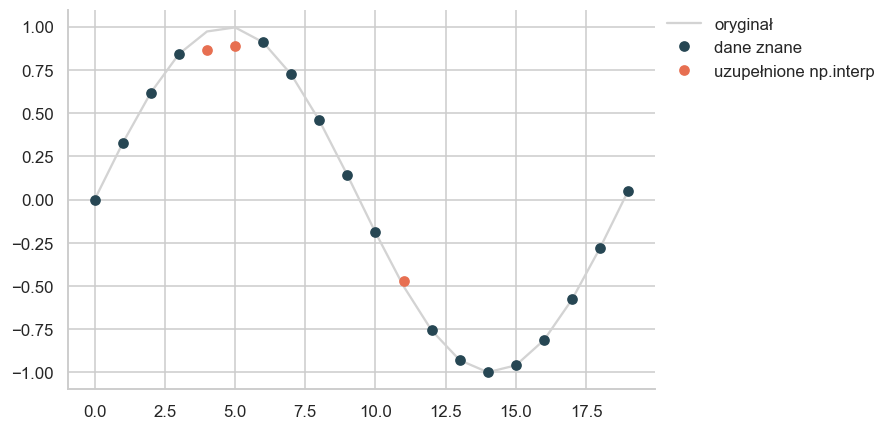

In [171]:
# a) uzupełnianie braków w szeregu o nierównych odstępach (interpolacja liniowa po wartościach X)
xs = np.arange(20, dtype=float)
ys = np.sin(xs / 3)
ys[[4, 5, 11]] = np.nan
miss = np.isnan(ys)
ys_filled = ys.copy()
ys_filled[miss] = np.interp(xs[miss], xs[~miss], ys[~miss])

# b) przeskalowanie do dowolnej skali odcinkowo-liniowej (np. punkty → ocena, lookup table)
score = np.array([10, 45, 62, 80, 99])
print(np.interp(score, [0, 50, 75, 100], [1, 3, 4, 5]))                        # 0→1, 50→3, 75→4, 100→5 z liniową interpolacją

# c) resampling szeregu na siatkę regularną (np. pomiary o nieregularnych czasach)
t_irreg = np.sort(rng.uniform(0, 10, 15))
v_irreg = np.sin(t_irreg) + rng.normal(0, 0.05, 15)
t_grid = np.linspace(0, 10, 11)
v_grid = np.interp(t_grid, t_irreg, v_irreg)

# d) wartość odpowiadająca percentylowi / percentyl wartości (odwrotność ECDF) bez scipy
s = np.sort(revenue)
cdf = np.linspace(0, 1, s.size)
print(np.interp(1000, s, cdf).round(3), np.interp(0.95, cdf, s).round(1), np.quantile(revenue, 0.95).round(1))

# e) dane cykliczne: godziny (period=24): interpolacja przez granicę doby
hours = np.array([22.0, 2.0])                                                    # 22:00 → 2:00 (zawija)
print(np.interp(0, hours % 24, [10.0, 50.0], period=24))

fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
ax.plot(xs, np.sin(xs / 3), color="lightgray", label="oryginał")
ax.plot(xs[~miss], ys[~miss], "o", color="#264653", label="dane znane")
ax.plot(xs[miss], ys_filled[miss], "o", color="#e76f51", label="uzupełnione np.interp")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
plt.show()

**Odpowiedniki:** `Series.interpolate(method=...)` (wiele metod, ale działa na indeksie Series), `scipy.interpolate.interp1d`/`CubicSpline` (gładsze). `np.interp` jest najszybszą liniową opcją dla dowolnych punktów zapytań i działa na surowych tablicach.

### 6.8. Zakres i różnice: `np.ptp`, `np.diff`, `np.gradient`, `np.trapezoid`

In [172]:
print(np.ptp(revenue))                                  # "peak to peak": max − min (zakres)
np.ptp(X, axis=0)                                # zakres każdej kolumny

1096.75


array([60.   ,  2.981,  9.   ,  0.497, 13.7  ])

| Funkcja | Parametry | Opis |
|---|---|---|
| `np.ptp(a, axis, keepdims)` | ✅ `a`; ⬜ `axis`, `out`, `keepdims` | Zakres `max − min` po osi. **Metoda `a.ptp()` została usunięta w NumPy 2.0**, używaj funkcji |
| `np.diff(a, n, axis)` | ✅ `a`; ⬜ `n` (rząd), `axis`, `prepend`, `append` | Różnice kolejnych elementów (`prepend=0` zachowuje długość) |
| `np.gradient(f, *varargs)` | ✅ `f`; ⬜ rozstaw/współrzędne, `axis` | Pochodna numeryczna (różnice centralne), zachowuje długość |
| `np.trapezoid(y, x)` | ✅ `y`; ⬜ `x`, `dx`, `axis` | Pole pod krzywą metodą trapezów (następca `np.trapz`) |
| `np.cumsum` + `np.diff` | | Wzajemnie odwrotne (z `prepend`) |

In [173]:
# a) wykrywanie stałych kolumn i skalowanie min-max z ochroną przed dzieleniem przez 0
rng_cols = np.ptp(X, axis=0)
const_cols = rng_cols == 0
scaled = (X - X.min(0)) / np.where(const_cols, 1, rng_cols)                  # stała kolumna → 0 zamiast NaN
print(rng_cols.round(2), const_cols)

# b) zmiany okres do okresu i zmiana procentowa; log-zwroty
prices = ts[:10]
print(np.diff(prices).round(2), (np.diff(prices) / prices[:-1]).round(4), np.diff(np.log(prices)).round(4))
print(np.diff(prices, prepend=prices[0]).round(2))                              # zachowanie długości (pierwsza zmiana = 0)

# c) pochodna numeryczna i pole pod krzywą
x_c = np.linspace(0, np.pi, 200)
print(np.trapezoid(np.sin(x_c), x_c).round(4), "≈ 2 (całka sin na [0, π])", np.gradient(np.sin(x_c), x_c)[[0, 100, 199]].round(3))

# d) pole pod krzywą ROC/PR (AUC) z punktów (patrz sekcja 10) i skumulowane pole
y_curve = np.array([0.0, 0.5, 0.8, 1.0]); x_curve = np.array([0.0, 0.2, 0.5, 1.0])
print(np.trapezoid(y_curve, x_curve))

[60.    2.98  9.    0.5  13.7 ] [False False False False False]
[  6.95   5.78  -5.33 -10.29  -6.55   4.12   4.86  13.53  -1.3 ] [ 0.07   0.055 -0.048 -0.097 -0.068  0.046  0.052  0.138 -0.012] [ 0.068  0.053 -0.049 -0.102 -0.071  0.045  0.051  0.129 -0.012]
[  0.     6.95   5.78  -5.33 -10.29  -6.55   4.12   4.86  13.53  -1.3 ]
2.0 ≈ 2 (całka sin na [0, π]) [ 1.    -0.008 -1.   ]
0.6950000000000001


### 6.9. Mini-katalog dodatkowych funkcji przydatnych w analizie

In [174]:
# --- przesunięcia i okna
a = np.arange(1, 8)
print(np.roll(a, 2))                              # cykliczne przesunięcie (lag z zawinięciem; początek wypełnij ręcznie)
print(np.convolve(a, np.ones(3) / 3, mode="valid"))   # średnia krocząca (okno 3)
print(np.correlate(a, a[::-1], mode="valid"))     # korelacja krzyżowa

# --- liczby i zaokrąglanie
print(np.round([0.5, 1.5, 2.5, 2.567], 1), np.round(2.5), np.round(3.5))      # zaokrąglanie "do parzystej" (banker's): 2.5→2, 3.5→4
print(np.floor(-1.5), np.ceil(-1.5), np.trunc(-1.5), np.rint(-1.5))           # w dół, w górę, ucięcie, do najbliższej całkowitej
print(np.divmod(17, 5), np.floor_divide(-7, 2), np.mod(-7, 2), np.fmod(-7, 2))   # iloraz i reszta (mod ma znak dzielnika, fmod dzielnej)
print(np.sign([-3, 0, 2]), np.copysign(5, -1), np.abs([-3, 2]), np.hypot(3, 4))  # znak, przeniesienie znaku, moduł, sqrt(a²+b²)

# --- funkcje stabilne numerycznie
print(np.log1p(1e-10), np.expm1(1e-10))                       # dokładne dla małych x (log(1+x), exp(x)−1)
print(np.logaddexp(np.log(2), np.log(3)))                     # log(2+3) bez przepełnienia (sumowanie w skali log)
print(np.heaviside([-1, 0, 1], 0.5))                          # funkcja schodkowa
print(np.nan_to_num(np.array([np.nan, np.inf, -np.inf, 1.0]), nan=0, posinf=1e9, neginf=-1e9))   # zamiana NaN/inf

# --- indeksy specjalne
print(np.tril(np.ones((3, 3))), np.triu(np.ones((3, 3)), k=1))  # trójkąty macierzy (np. górny trójkąt korelacji)
print(np.tril_indices(3, k=-1), np.diag_indices(3))             # indeksy trójkąta/przekątnej
print(np.take_along_axis(np.array([[3, 1, 2], [9, 7, 8]]), np.array([[1], [2]]), axis=1))   # wybór po jednym elemencie w wierszu

# --- porównywanie, wyszukiwanie wartości
print(np.nanargmax([1, np.nan, 5]), np.argmax(np.array([1, 5, 5])))   # pierwszy indeks maksimum, z NaN i bez
print(np.flatnonzero(np.diff(np.sign(np.array([-1, 2, 3, -4, -5, 6])))))   # indeksy zmian znaku

# --- wielomiany i dopasowanie krzywej
coef = np.polynomial.Polynomial.fit(np.arange(10.0), np.arange(10.0) ** 2, deg=2).convert().coef
print(coef.round(3), np.polyval([1, 0, 0], 3))                # nowy API: np.polynomial; polyfit/polyval to starszy interfejs

# --- einsum: zwięzłe sumowania i iloczyny (sekcja 7)
np.einsum("ij->j", X)[:3], np.einsum("ij,ij->i", X[:3], X[:3])        # suma po kolumnach; iloczyn skalarny wierszy

[6 7 1 2 3 4 5]
[2. 3. 4. 5. 6.]
[84]
[0.5 1.5 2.5 2.6] 2.0 4.0
-2.0 -1.0 -1.0 -2.0
(3, 2) -4 1 -1
[-1  0  1] -5.0 [3 2] 5.0
9.999999999500001e-11 1.00000000005e-10
1.6094379124341005
[0.  0.5 1. ]
[ 0.e+00  1.e+09 -1.e+09  1.e+00]
[[1. 0. 0.]
 [1. 1. 0.]
 [1. 1. 1.]] [[0. 1. 1.]
 [0. 0. 1.]
 [0. 0. 0.]]
(array([1, 2, 2]), array([0, 0, 1])) (array([0, 1, 2]), array([0, 1, 2]))
[[1]
 [8]]
2 1
[0 2 4]
[ 0. -0.  1.] 9


(array([39837.   ,  8159.312,  3919.   ]),
 array([2162.562,  864.082, 2525.737]))

## 7. Algebra liniowa

#### Wersja podstawowa

In [175]:
A = np.array([[2.0, 1.0], [1.0, 3.0]])
b = np.array([1.0, 2.0])

print(A @ A)                          # iloczyn macierzowy (operator @, nie *; * jest elementowe)
print(A.T)                            # transpozycja
print(np.linalg.solve(A, b))          # rozwiązanie układu A·x = b  (zamiast inv(A) @ b)
np.linalg.inv(A), np.linalg.det(A)

[[ 5.  5.]
 [ 5. 10.]]
[[2. 1.]
 [1. 3.]]
[0.2 0.6]


(array([[ 0.6, -0.2],
        [-0.2,  0.4]]),
 5.000000000000001)

| Funkcja | Parametry | Opis / uwagi |
|---|---|---|
| `A @ B`, `np.matmul(A, B)` | ✅ `A`, `B` | Iloczyn macierzowy, obsługuje partie (`(k, n, m) @ (m, p)`) |
| `np.dot(a, b)` | ✅ | Dla 1D iloczyn skalarny, dla 2D mnożenie macierzy; dla ND bardziej zawiłe, więc woli się `@`/`einsum` |
| `np.vecdot(a, b)` | ✅ `axis=-1` ⬜ | Iloczyn skalarny wzdłuż osi (NumPy ≥ 2.0) |
| `np.outer(a, b)`, `np.inner`, `np.tensordot(a, b, axes)` | | Iloczyn zewnętrzny, wewnętrzny, kontrakcja osi |
| `np.einsum("ij,jk->ik", A, B)` | ✅ zapis indeksów + operandy; ⬜ `optimize` | Zwięzły zapis sum po indeksach (poniżej) |
| `np.linalg.norm(x, ord, axis, keepdims)` | ✅ `x`; ⬜ `ord` (`None`=L2, `1`, `np.inf`, `"fro"`), `axis` | Normy wektorów/macierzy; `axis=1` = norma każdego wiersza |
| `np.linalg.solve(A, b)` | ✅ obie | Rozwiązanie układu (stabilniej i szybciej niż `inv`) |
| `np.linalg.lstsq(A, b, rcond)` | ✅ obie; ⬜ `rcond` | Rozwiązanie najmniejszych kwadratów (regresja); zwraca `(x, residuals, rank, sv)` |
| `np.linalg.inv`, `pinv` | ✅ `A` | Odwrotność / pseudo-odwrotność (Moore–Penrose, dla układów nieoznaczonych) |
| `np.linalg.det`, `matrix_rank`, `cond`, `trace` | ✅ `A` | Wyznacznik, rząd, współczynnik uwarunkowania (duży = niestabilne obliczenia) |
| `np.linalg.eig`, `np.linalg.eigh` | ✅ `A` | Wartości/wektory własne; `eigh` dla macierzy **symetrycznych** (kowariancja; szybsze, rzeczywiste, posortowane rosnąco) |
| `np.linalg.svd(A, full_matrices)` | ✅ `A`; ⬜ `full_matrices=False` | Rozkład SVD: `A = U·diag(S)·Vt` |
| `np.linalg.qr`, `np.linalg.cholesky` | ✅ `A` | Rozkłady QR i Choleskiego (macierze dodatnio określone) |

In [176]:
# a) regresja liniowa (OLS): lstsq jest stabilne numerycznie; równania normalne: solve(XtX, Xty)
beta_true = np.array([2.0, 0.5, -1.0, 3.0, 0.1])
y_reg = X @ beta_true + 5 + rng.normal(0, 1, n)
X1 = np.column_stack([np.ones(n), X])                                        # kolumna jedynek = wyraz wolny
beta_lstsq, *_ = np.linalg.lstsq(X1, y_reg, rcond=None)
beta_normal = np.linalg.solve(X1.T @ X1, X1.T @ y_reg)                         # równania normalne (szybkie, gorsze uwarunkowanie)
print(beta_lstsq.round(3), np.allclose(beta_lstsq, beta_normal))

from sklearn.linear_model import LinearRegression, Ridge
lr_sk = LinearRegression().fit(X, y_reg)
print(np.r_[lr_sk.intercept_, lr_sk.coef_].round(3))                           # te same współczynniki

# b) regresja grzbietowa (Ridge) w postaci zamkniętej: (XᵀX + λI)⁻¹ Xᵀy (bez karania wyrazu wolnego)
Zs = (X - X.mean(0)) / X.std(0)
lam = 10.0
beta_ridge = np.linalg.solve(Zs.T @ Zs + lam * np.eye(Zs.shape[1]), Zs.T @ (y_reg - y_reg.mean()))
print(beta_ridge.round(4), Ridge(alpha=lam).fit(Zs, y_reg).coef_.round(4))

# c) podobieństwo cosinusowe wszystkich par wierszy: normalizacja + jeden iloczyn macierzowy
U = Zs[:6]
Un = U / np.linalg.norm(U, axis=1, keepdims=True)
cos_sim = Un @ Un.T
print(cos_sim.round(2))

# d) odległość Mahalanobisa (uwzględnia korelacje cech): d² = (x−μ)ᵀ Σ⁻¹ (x−μ), policzone dla wszystkich wierszy
mu = X.mean(0)
cov_inv = np.linalg.inv(np.cov(X, rowvar=False))
diff = X - mu
d2 = np.einsum("ij,jk,ik->i", diff, cov_inv, diff)                               # bez pętli po wierszach
print(d2[:5].round(2), np.argsort(d2)[-3:])                                      # największe = najbardziej nietypowe obserwacje

# e) PCA przez SVD i przez eigh kowariancji (to samo, inne drogi)
Zc = Zs - Zs.mean(0)
U_, S, Vt = np.linalg.svd(Zc, full_matrices=False)
explained = S ** 2 / np.sum(S ** 2)                                              # udział wariancji
scores = Zc @ Vt.T                                                               # współrzędne w nowych osiach (PC)
evals, evecs = np.linalg.eigh(np.cov(Zc, rowvar=False))
print(explained.round(3), (evals[::-1] / evals.sum()).round(3))                  # eigh zwraca rosnąco → odwracamy

from sklearn.decomposition import PCA
print(PCA().fit(Zs).explained_variance_ratio_.round(3))                          # weryfikacja

# f) einsum: zwięzłe zapisy typowych operacji
A3 = rng.random((4, 3, 2)); B3 = rng.random((4, 2, 5))
print(np.einsum("bij,bjk->bik", A3, B3).shape, np.allclose(np.einsum("bij,bjk->bik", A3, B3), A3 @ B3))   # mnożenie w partiach
print(np.einsum("ii->", np.eye(3)), np.einsum("i,j->ij", [1, 2], [3, 4]), np.einsum("ij->i", Zs)[:3])      # ślad, iloczyn zewnętrzny, sumy wierszy

[ 5.527  1.996  0.463 -0.986  2.726  0.084] True
[ 5.527  1.996  0.463 -0.986  2.726  0.084]
[22.672  0.231 -1.667  0.226  0.181] [22.672  0.231 -1.667  0.226  0.181]
[[ 1.    0.09  0.89  0.08 -0.13  0.61]
 [ 0.09  1.   -0.24  0.21  0.11  0.46]
 [ 0.89 -0.24  1.   -0.   -0.28  0.24]
 [ 0.08  0.21 -0.    1.   -0.84  0.17]
 [-0.13  0.11 -0.28 -0.84  1.    0.19]
 [ 0.61  0.46  0.24  0.17  0.19  1.  ]]
[22.89  4.56  4.04  7.01  6.44] [190 993 957]
[0.215 0.208 0.2   0.191 0.185] [0.215 0.208 0.2   0.191 0.185]
[0.215 0.208 0.2   0.191 0.185]
(4, 3, 5) True
3.0 [[3 4]
 [6 8]] [ 3.872 -0.757  1.494]


> **Praktyczne zasady:** (1) zamiast `inv(A) @ b` używaj `solve(A, b)`; (2) sprawdzaj `np.linalg.cond(A)`: gdy bardzo duże (> 1e10), wyniki są niewiarygodne (silna współliniowość cech); (3) dla macierzy symetrycznych (kowariancji) używaj `eigh`; (4) do regresji preferuj `lstsq` lub `np.linalg.svd`; (5) `float32` zmniejsza pamięć, ale zmniejsza też dokładność rozkładów.

## 8. Losowość: `Generator`

#### Wersja podstawowa

In [177]:
rng = np.random.default_rng(42)         # generator z ziarnem (powtarzalne wyniki)
print(rng.random(3))                           # 3 liczby z [0, 1)
print(rng.integers(1, 7, size=5))              # 5 rzutów kostką (1–6; górna granica wyłączona!)
rng.normal(0, 1, size=3)                # rozkład normalny N(0, 1)

[0.774 0.439 0.859]
[1 5 2 1 4]


array([ 0.128, -0.316, -0.017])

Używaj **`np.random.default_rng`** (nowy API), a nie starych `np.random.seed()` / `np.random.rand()` (globalny stan, gorsze generatory).

| Metoda `rng.` | Opis | Parametry (✅ / ⬜) |
|---|---|---|
| `random(size)` | Rozkład jednostajny [0, 1) | ⬜ `size`, `dtype` |
| `integers(low, high, size)` | Liczby całkowite z `[low, high)` | ✅ `low`; ⬜ `high`, `size`, `endpoint=True` (włącza `high`) |
| `normal(loc, scale, size)` | Normalny | ⬜ wszystkie (domyślnie N(0,1)) |
| `uniform`, `lognormal`, `exponential`, `gamma`, `beta`, `poisson`, `binomial`, `multinomial`, `multivariate_normal`, `standard_t`, `chisquare` | Pozostałe rozkłady | `size` ⬜ |
| `choice(a, size, replace, p, axis, shuffle)` | Losowanie z tablicy | ✅ `a`; ⬜ `size`, `replace=True`, `p` (wagi), `shuffle` |
| `permutation(x)` / `shuffle(x)` | Losowa permutacja (kopia) / w miejscu | ✅ `x` (liczba n → permutacja `arange(n)`) |
| `spawn(k)` | Niezależne generatory (obliczenia równoległe) | ✅ `k` |

In [178]:
# a) podział train/test (z permutacją) i stratyfikowany
idx = rng.permutation(n)
cut = int(0.8 * n)
train_idx, test_idx = idx[:cut], idx[cut:]
print(train_idx.size, test_idx.size, y[train_idx].mean().round(3), y[test_idx].mean().round(3))

strat_test = np.concatenate([rng.choice(np.flatnonzero(y == c), int(0.2 * (y == c).sum()), replace=False) for c in np.unique(y)])
print(y[strat_test].mean().round(3), y.mean().round(3))                         # udział klas zachowany

# b) bootstrap: przedział ufności średniej (wektorowo: macierz (B, n) losowań)
B = 5000
boot = rng.choice(revenue, size=(B, revenue.size), replace=True).mean(axis=1)
ci = np.percentile(boot, [2.5, 97.5])
print(revenue.mean().round(2), ci.round(2))

# c) test permutacyjny różnicy średnich (powracający vs nowi): bez założeń o rozkładzie
g1, g2 = revenue[is_returning], revenue[~is_returning]
obs = g1.mean() - g2.mean()
pooled = np.concatenate([g1, g2])
perm = np.array([rng.permutation(pooled) for _ in range(5000)])                  # 5000 permutacji etykiet
perm_diff = perm[:, :g1.size].mean(axis=1) - perm[:, g1.size:].mean(axis=1)
p_value = (np.abs(perm_diff) >= abs(obs)).mean()
print(f"różnica = {obs:.2f}, p ≈ {p_value:.3f}")

# d) symulacja Monte Carlo: ryzyko przekroczenia budżetu przy niepewnych kosztach
costs = rng.lognormal(mean=[3.0, 2.5, 2.0], sigma=0.4, size=(100_000, 3))        # 3 pozycje kosztowe
total = costs.sum(axis=1)
print(f"P(koszt > 60) = {(total > 60).mean():.3f}, 95. percentyl = {np.percentile(total, 95):.1f}")

# e) losowanie z wagami, skorelowane dane (multivariate_normal), powtarzalność
print(rng.choice(["A", "B", "C"], size=10, p=[0.7, 0.2, 0.1]))
cov = np.array([[1.0, 0.8], [0.8, 1.0]])
pair = rng.multivariate_normal([0, 0], cov, size=2000)
print(np.corrcoef(pair, rowvar=False)[0, 1].round(2))
a1 = np.random.default_rng(7).random(3); a2 = np.random.default_rng(7).random(3)
print(np.array_equal(a1, a2))                                                     # to samo ziarno = te same liczby
children = np.random.default_rng(1).spawn(3)                                      # niezależne strumienie dla 3 procesów/wątków

800 200 0.48 0.485
0.482 0.481


243.9 [235.3  253.25]
różnica = -2.60, p ≈ 0.788
P(koszt > 60) = 0.075, 95. percentyl = 63.5
['C' 'B' 'B' 'B' 'A' 'A' 'A' 'A' 'A' 'C']
0.81
True


## 9. Szeregi czasowe, okna kroczące i daty

### 9.1. Okna kroczące bez pętli

#### Wersja podstawowa

In [179]:
w = 7
np.convolve(ts, np.ones(w) / w, mode="valid")[:5]          # średnia krocząca (okno 7), skracająca szereg do n−w+1

array([100.099, 100.034, 100.909, 100.772, 100.133])

In [180]:
from numpy.lib.stride_tricks import sliding_window_view

win = sliding_window_view(ts, window_shape=7)               # widok (n−6, 7), bez kopiowania pamięci
print(win.shape, win.mean(axis=1)[:3], win.std(axis=1, ddof=1)[:3], win.max(axis=1)[:3])

(724, 7) [100.099 100.034 100.909] [7.94  7.955 8.956] [111.485 111.485 111.828]


| Metoda | Co liczy | Uwagi |
|---|---|---|
| `np.convolve(a, kernel, mode)` | Średnia/ważona krocząca (jądro = wagi) | `mode`: `"valid"` (bez brzegów), `"same"`, `"full"` |
| `sliding_window_view(a, window_shape, axis)` | Okna jako widok | Dowolna statystyka po osi okna: `mean`, `std`, `max`, `quantile`, `median` |
| trik `cumsum` | Suma/średnia krocząca w O(n) niezależnie od okna | `c = np.cumsum(np.r_[0, a]); (c[w:] - c[:-w]) / w` |
| `np.diff`, `np.roll`, slicing | Zmiany, opóźnienia (lag) | |

True True
[120 350 610] [ 3.3 -6.4  6. ]
[6.131 0.235 0.715] R² = 0.85


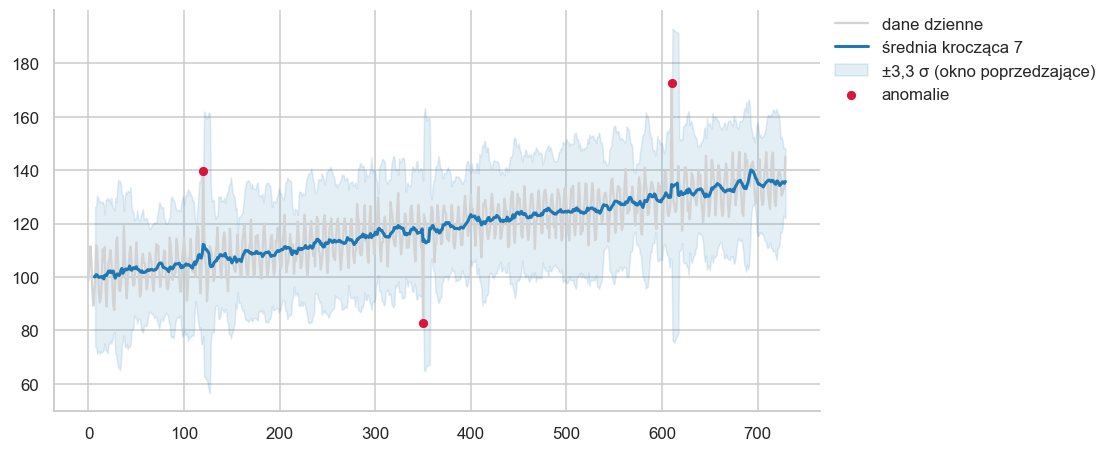

In [181]:
w = 7
c = np.cumsum(np.r_[0, ts])
roll_mean = (c[w:] - c[:-w]) / w                                              # trik cumsum
roll_std = sliding_window_view(ts, w).std(axis=1, ddof=1)
print(np.allclose(roll_mean, sliding_window_view(ts, w).mean(1)), np.allclose(roll_mean, pd.Series(ts).rolling(w).mean().dropna()))

# wyrównanie długości: wyniki "valid" przypisujemy do końca okna (jak pandas) i dopełniamy NaN na początku
rm_full = np.full(ts.size, np.nan); rm_full[w - 1:] = roll_mean
rs_full = np.full(ts.size, np.nan); rs_full[w - 1:] = roll_std

# anomalie: porównaj punkt ze statystykami OKNA POPRZEDZAJĄCEGO (bez bieżącego punktu).
# Okno zawierające sam punkt zawyża σ i "maskuje" anomalię (w oknie n=7 pojedyncza wartość nie może przekroczyć |z| ≈ 2,27)
prev = sliding_window_view(ts[:-1], w)                       # okno obserwacji tuż przed każdym punktem (od indeksu w)
mu_p, sd_p = prev.mean(axis=1), prev.std(axis=1, ddof=1)
z = np.full(ts.size, np.nan)
z[w:] = (ts[w:] - mu_p) / sd_p
anom = np.flatnonzero(np.abs(z) > 3.3)                       # próg dobrany do danych; zbyt niski generuje fałszywe alarmy
print(anom, np.round(z[anom], 1))                            # wstrzyknięto anomalie w 120, 350, 610

# cechy opóźnione (lag) i różnice dla modeli: wszystko slicingiem
lag1, lag7 = ts[6:-1], ts[:-7]                                                # aligned: ts[7:] ma lag1 = ts[6:-1], lag7 = ts[:-7]
target = ts[7:]
Xlag = np.column_stack([np.ones(target.size), lag1, lag7])
beta, *_ = np.linalg.lstsq(Xlag, target, rcond=None)
print(beta.round(3), "R² =", (1 - ((target - Xlag @ beta) ** 2).sum() / ((target - target.mean()) ** 2).sum()).round(3))

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.plot(t, ts, color="lightgray", label="dane dzienne")
ax.plot(t, rm_full, color="#1f77b4", linewidth=2, label="średnia krocząca 7")
band_lo, band_hi = np.full(ts.size, np.nan), np.full(ts.size, np.nan)
band_lo[w:], band_hi[w:] = mu_p - 3.3 * sd_p, mu_p + 3.3 * sd_p
ax.fill_between(t, band_lo, band_hi, color="#1f77b4", alpha=0.12, label="±3,3 σ (okno poprzedzające)")
ax.scatter(anom, ts[anom], color="crimson", s=25, zorder=3, label="anomalie")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
plt.show()

### 9.2. Sezonowość i autokorelacja

In [182]:
# profil tygodniowy: przycięcie do pełnych tygodni + reshape (tydzień w wierszu) + średnia po wierszach
weeks = ts[: (ts.size // 7) * 7].reshape(-1, 7)
detr = weeks - np.polyval(np.polyfit(np.arange(weeks.size), weeks.ravel(), 1), np.arange(weeks.size)).reshape(-1, 7)   # usunięcie trendu liniowego
print(detr.mean(axis=0).round(2))                                                                                        # średni efekt dnia cyklu

# autokorelacja (ACF) przez korelację krzyżową
x = ts - ts.mean()
acf = np.correlate(x, x, mode="full")[x.size - 1:]
acf = acf / acf[0]
print(acf[:10].round(2), "→ pik przy opóźnieniu 7 = sezonowość tygodniowa:", acf[7].round(2))

[-0.    6.91  8.13  3.45 -3.64 -8.21 -6.64]
[1.   0.83 0.63 0.48 0.48 0.63 0.82 0.89 0.81 0.62] → pik przy opóźnieniu 7 = sezonowość tygodniowa: 0.89


### 9.3. Daty: `datetime64` i `timedelta64`

In [183]:
d = np.datetime64("2024-03-15")
print(d + np.timedelta64(30, "D"), d + np.timedelta64(2, "W"), np.datetime64("2024-03-15T10:30"), np.datetime64("2024-03", "M"))
days = np.arange("2024-01-01", "2024-01-10", dtype="datetime64[D]")                  # zakres dat
print(days[:3], np.diff(days[[0, -1]]), (days[-1] - days[0]).astype(int))             # różnica jako timedelta64[D]

# cechy z dat bez pandas
months = order_date.astype("datetime64[M]")                                            # obcięcie do miesiąca
years = order_date.astype("datetime64[Y]").astype(int) + 1970
month_no = months.astype(int) % 12 + 1
weekday = (order_date.astype("int64") + 3) % 7                                         # 1970-01-01 to czwartek → poniedziałek = 0
print(years[:3], month_no[:3], weekday[:3])

# agregacja miesięczna: unikalne miesiące + kody (inverse) + bincount z wagami
uniq_m, inv = np.unique(months, return_inverse=True)
monthly = np.bincount(inv, weights=revenue)
print(uniq_m[:3], monthly[:3].round(0))

# dni robocze
print(np.busday_count("2024-03-01", "2024-04-01"), np.is_busday(np.datetime64("2024-03-16")), np.busday_offset("2024-03-15", 5, roll="forward"))
print(np.datetime_as_string(days[:2]), np.isnat(np.array(["2024-01-01", "NaT"], dtype="datetime64[D]")))

2024-04-14 2024-03-29 2024-03-15T10:30 2024-03
['2024-01-01' '2024-01-02' '2024-01-03'] [8] 8
[2023 2024 2023] [5 3 8] [1 1 5]
['2023-01' '2023-02' '2023-03'] [ 8927.  9180. 14083.]
21 False 2024-03-22
['2024-01-01' '2024-01-02'] [False  True]


> Dla złożonych operacji kalendarzowych (strefy czasowe, częstotliwości, `resample`) wygodniejsze są pandas/Polars; `datetime64` wystarcza do szybkich obliczeń wektorowych.

## 10. NumPy w ML: implementacje od zera i weryfikacja z scikit-learn

Poniższe implementacje nie zastępują scikit-learn, ale pokazują, **jak działają algorytmy**, a wektorowe techniki (broadcasting, `argpartition`, `bincount`, `einsum`) przenoszą się na własne rozwiązania i debugowanie. Każdy wynik jest porównany z odpowiednikiem scikit-learn.

### 10.1. Przygotowanie danych

In [184]:
Zs = (X - X.mean(0)) / X.std(0)                                                     # standaryzacja cech (dopasuj na train, zastosuj na test!)
idx = np.random.default_rng(0).permutation(n)
tr, te = idx[:800], idx[800:]
mu, sd = X[tr].mean(0), X[tr].std(0)                                                  # parametry TYLKO z treningu (bez wycieku danych)
Xtr, Xte = (X[tr] - mu) / sd, (X[te] - mu) / sd
ytr, yte = y[tr], y[te]

onehot = np.eye(5)[satisfaction - 1]                                                  # one-hot przez indeksowanie macierzy jednostkowej
print(onehot[:3], onehot.shape)

# stabilne numerycznie funkcje: sigmoid i softmax
sigmoid = lambda z_: np.exp(-np.logaddexp(0, -z_))                                    # = 1/(1+e^{-z}) bez przepełnień
logits = np.array([[1000.0, 1001.0, 999.0], [0.1, 0.2, 0.3]])
soft = np.exp(logits - logits.max(axis=1, keepdims=True))                            # odjęcie maksimum = ta sama wartość, brak overflow
soft /= soft.sum(axis=1, keepdims=True)
print(sigmoid(np.array([-1000.0, 0.0, 1000.0])), soft.round(3))

[[0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]] (1000, 5)
[0.  0.5 1. ] [[0.245 0.665 0.09 ]
 [0.301 0.332 0.367]]


### 10.2. Regresja logistyczna (spadek gradientowy) i porównanie z scikit-learn

In [185]:
Xb = np.column_stack([np.ones(Xtr.shape[0]), Xtr])                                   # wyraz wolny jako kolumna jedynek
w = np.zeros(Xb.shape[1])
lr = 0.5
losses = []
for epoch in range(800):
    p = sigmoid(Xb @ w)
    grad = Xb.T @ (p - ytr) / ytr.size                                                # gradient straty log-loss (całość wektorowo)
    w -= lr * grad
    if epoch % 50 == 0:
        eps = 1e-12
        losses.append(-np.mean(ytr * np.log(p + eps) + (1 - ytr) * np.log(1 - p + eps)))
print(np.round(losses[:3], 4), np.round(losses[-1], 4))                               # strata maleje

from sklearn.linear_model import LogisticRegression
sk = LogisticRegression(C=1e10, max_iter=2000).fit(Xtr, ytr)                         # bardzo słaba regularyzacja = zwykła regresja logistyczna
print(w.round(3), np.r_[sk.intercept_, sk.coef_.ravel()].round(3))                    # niemal identyczne współczynniki

Xb_te = np.column_stack([np.ones(Xte.shape[0]), Xte])
p_te = sigmoid(Xb_te @ w)
pred = (p_te >= 0.5).astype(int)

[0.693 0.524 0.523] 0.5227
[ 0.04   0.066 -0.346  0.042 -0.485  1.58 ] [ 0.04   0.066 -0.346  0.042 -0.485  1.58 ]


### 10.3. Metryki klasyfikacji: macierz pomyłek, F1, AUC (bez pętli)

In [186]:
# macierz pomyłek: kod = 2*y_true + y_pred, potem bincount
cm = np.bincount(2 * yte + pred, minlength=4).reshape(2, 2)                          # [[TN, FP], [FN, TP]]
tn, fp, fn, tp = cm.ravel()
accuracy = (tp + tn) / cm.sum()
precision, recall = tp / (tp + fp), tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

# ROC AUC przez rangi (statystyka Manna–Whitneya): P(score_pos > score_neg)
ranks = np.argsort(np.argsort(p_te)) + 1                                              # rangi 1..n (bez obsługi remisów)
n_pos, n_neg = yte.sum(), (1 - yte).sum()
auc = (ranks[yte == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

# krzywa ROC: sortowanie po malejącym score + kumulatywne TP/FP + pole trapezami
order = np.argsort(-p_te)
tps = np.cumsum(yte[order]); fps = np.cumsum(1 - yte[order])
tpr, fpr = np.r_[0, tps / n_pos], np.r_[0, fps / n_neg]
auc_trap = np.trapezoid(tpr, fpr)

from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, log_loss
print(cm.tolist(), confusion_matrix(yte, pred).tolist())
print(round(f1, 4), round(f1_score(yte, pred), 4), "|", round(auc, 4), round(auc_trap, 4), round(roc_auc_score(yte, p_te), 4))
print(round(-np.mean(yte * np.log(p_te) + (1 - yte) * np.log(1 - p_te)), 4), round(log_loss(yte, p_te), 4))

[[83, 20], [31, 66]] [[83, 20], [31, 66]]
0.7213 0.7213 | 0.8247 0.8247 0.8247
0.5166 0.5166


### 10.4. k-means od zera (broadcasting + `bincount`/`add.at`)

In [187]:
k = 3
best = None
for init in range(10):                                                                # kilka inicjalizacji (jak n_init w sklearn): lokalne minima
    r = np.random.default_rng(init)
    centers = Zs[r.choice(n, k, replace=False)]
    for it in range(100):
        d2 = ((Zs[:, None, :] - centers[None, :, :]) ** 2).sum(-1)                   # (n, k) kwadraty odległości do centrów
        labels = d2.argmin(axis=1)
        counts = np.bincount(labels, minlength=k)
        sums = np.zeros_like(centers)
        np.add.at(sums, labels, Zs)                                                   # sumy punktów w klastrach (powtarzające się indeksy!)
        new_centers = np.where(counts[:, None] > 0, sums / np.maximum(counts, 1)[:, None], centers)   # pusty klaster: zostaje stary centrum
        if np.allclose(new_centers, centers):
            break
        centers = new_centers
    inertia = d2[np.arange(n), labels].sum()
    if best is None or inertia < best[0]:
        best = (inertia, labels.copy(), centers.copy())

from sklearn.cluster import KMeans
print(round(best[0], 2), round(KMeans(k, n_init=10, random_state=0).fit(Zs).inertia_, 2), np.bincount(best[1]))   # wyniki bliskie, ale nie identyczne: sklearn używa inicjalizacji k-means++

3757.57 3761.65 [354 396 250]


### 10.5. kNN od zera (`argpartition`) i walidacja krzyżowa na indeksach

In [188]:
k_nn = 15
D = np.sqrt(((Xte[:, None, :] - Xtr[None, :, :]) ** 2).sum(-1))                      # (200, 800) macierz odległości test×train
nn_idx = np.argpartition(D, k_nn, axis=1)[:, :k_nn]                                    # k najbliższych bez pełnego sortowania
votes = ytr[nn_idx].mean(axis=1)                                                       # udział klasy 1 wśród sąsiadów
pred_knn = (votes >= 0.5).astype(int)

from sklearn.neighbors import KNeighborsClassifier
print(round((pred_knn == yte).mean(), 3), round(KNeighborsClassifier(k_nn).fit(Xtr, ytr).score(Xte, yte), 3))

# walidacja krzyżowa k-fold: tylko indeksy (permutacja + array_split)
folds = np.array_split(np.random.default_rng(1).permutation(n), 5)
acc = []
for i in range(5):
    val_i = folds[i]
    trn_i = np.concatenate([folds[j] for j in range(5) if j != i])
    m_, s_ = X[trn_i].mean(0), X[trn_i].std(0)
    Xa, Xv = (X[trn_i] - m_) / s_, (X[val_i] - m_) / s_
    Dv = np.sqrt(((Xv[:, None, :] - Xa[None, :, :]) ** 2).sum(-1))
    nn_v = np.argpartition(Dv, k_nn, axis=1)[:, :k_nn]
    acc.append(((y[trn_i][nn_v].mean(1) >= 0.5).astype(int) == y[val_i]).mean())
print(np.round(acc, 3), np.mean(acc).round(3))

0.725 0.725
[0.7   0.715 0.685 0.76  0.73 ] 0.718


### 10.6. Mini-batche i trening w epokach

In [189]:
batch = 64
wb = np.zeros(Xb.shape[1])
r = np.random.default_rng(3)
for epoch in range(30):
    perm = r.permutation(Xb.shape[0])                                                  # tasowanie na początku epoki
    for start in range(0, perm.size, batch):
        ib = perm[start:start + batch]                                                 # indeksy partii
        pb = sigmoid(Xb[ib] @ wb)
        wb -= 0.3 * Xb[ib].T @ (pb - ytr[ib]) / ib.size
print(wb.round(3), (sigmoid(Xb_te @ wb) >= 0.5).astype(int).__eq__(yte).mean().round(3))

[-0.012  0.055 -0.322  0.041 -0.489  1.586] 0.735


## 11. Wydajność i pamięć

### 11.1. Wektoryzacja vs pętle

**Zasada:** pętla po elementach w Pythonie to ~50–200× wolniejsza operacja niż ta sama operacja wektorowa. Szukaj sformułowania przez `where`/`select`/`clip`/`maximum`, broadcasting, `bincount`, `einsum`, `cumsum`.

In [190]:
import time

big = rng.random(2_000_000)

t0 = time.perf_counter()
s_loop = 0.0
for v in big[:200_000]:                                  # pętla na 10% danych
    s_loop += v * v
t_loop = (time.perf_counter() - t0) * 10                 # ekstrapolacja do pełnych danych

t0 = time.perf_counter()
s_vec = np.dot(big, big)                                 # wektorowo (cały zbiór)
t_vec = time.perf_counter() - t0
print(f"pętla ≈ {t_loop:.3f} s, wektorowo = {t_vec:.4f} s → ok. {t_loop / t_vec:,.0f}× szybciej")

pętla ≈ 1.828 s, wektorowo = 0.0043 s → ok. 426× szybciej


### 11.2. Pamięć: typy, widoki, kopie, operacje „w miejscu"

| Technika | Efekt |
|---|---|
| Mniejszy `dtype` (`float32` zamiast `float64`, `int32`/`int16`/`uint8` zamiast `int64`) | 2–8× mniej pamięci (uwaga na zakres i precyzję) |
| Widoki zamiast kopii (slicing, `reshape`, `T`, `ravel`) | Zero kopiowania |
| Operacje w miejscu: `a += b`, `np.add(a, b, out=a)` | Bez alokacji tymczasowej tablicy |
| Wstępna alokacja (`np.empty`, `np.zeros`) zamiast `append` w pętli | Unika wielokrotnego kopiowania |
| `np.concatenate` **raz** na końcu (zbieraj w liście) | Zamiast sklejania w pętli (O(n²)) |
| Kolejność pamięci (`order="C"`/`"F"`, `np.ascontiguousarray`) | Szybsze operacje po osi zgodnej z układem |
| `np.memmap`, `np.load(..., mmap_mode="r")` | Praca na danych większych niż RAM |
| `a.nbytes`, `np.shares_memory`, `a.flags` | Diagnostyka |

In [191]:
a64 = np.zeros(5_000_000)
a32 = a64.astype(np.float32)
print(a64.nbytes / 1e6, "MB →", a32.nbytes / 1e6, "MB")

# operacje w miejscu: brak nowej tablicy
x = rng.random(1_000_000); y_ = rng.random(1_000_000)
np.add(x, y_, out=x)                                    # x = x + y bez alokacji (zapis do x)
x *= 2                                                  # in-place

# układ pamięci: widok czy kopia zależy od ciągłości danych
M = rng.random((3000, 3000))
print(M.flags["C_CONTIGUOUS"], M.T.flags["C_CONTIGUOUS"], M.T.flags["F_CONTIGUOUS"])                  # transpozycja to widok o układzie Fortran
print(np.shares_memory(M, M.reshape(-1)), np.shares_memory(M, M.T.reshape(-1)))                       # reshape(-1) z M: widok; z M.T: KOPIA (dane nieciągłe)
Mt = np.ascontiguousarray(M.T)                                                                        # jawna kopia w układzie C (przed wielokrotnym użyciem, np. w pętli)
print(Mt.flags["C_CONTIGUOUS"])

# wstępna alokacja vs append
res = np.empty(1000)
for i in range(res.size):
    res[i] = i ** 2                                     # zapis do gotowej tablicy (lista + np.array(list) też bywa OK)

40.0 MB → 20.0 MB
True False True
True False
True


### 11.4. Dokładność liczb i ostrzeżenia

In [192]:
print(np.float32(0.1) + np.float32(0.2) == np.float32(0.3), 0.1 + 0.2 == 0.3, np.isclose(0.1 + 0.2, 0.3))      # porównuj z tolerancją
print(np.finfo(np.float64).eps, np.finfo(np.float32).eps, np.iinfo(np.int32).max)                             # zakresy

big_vals = np.array([1e16, 1.0, -1e16])
print(big_vals.sum(), np.sum(big_vals[[0, 2, 1]]))                                                              # kolejność sumowania a wynik (utrata precyzji)
print(np.array([200], dtype=np.uint8) + 100)                                                                    # przepełnienie: 44, bez ostrzeżenia

with np.errstate(divide="ignore", invalid="ignore"):                                                            # wyciszenie ostrzeżeń w bloku
    print(np.array([1.0, 0.0]) / np.array([0.0, 0.0]))
with np.errstate(all="raise"):                                                                                  # lub zamiana na wyjątki (diagnostyka)
    try:
        np.array([1.0]) / np.array([0.0])
    except FloatingPointError as e:
        print("wyjątek:", e)

True False True
2.220446049250313e-16 1.1920929e-07 2147483647
0.0 1.0
[44]
[inf nan]
wyjątek: divide by zero encountered in divide


> Przy ciężkich pętlach, których nie da się zwektoryzować, rozważ **Numba** (`@njit`), a dla obliczeń na GPU/automatycznego różniczkowania **JAX**/**CuPy**/PyTorch (API zbliżone do NumPy).

## 12. Braki danych i tablice maskowane

NaN istnieje **tylko w typach zmiennoprzecinkowych**. Tablica całkowita nie przechowa braku (rzutowanie na `float`). `np.nan == np.nan` jest `False`, a każde działanie z NaN daje NaN.

#### Wersja podstawowa

In [193]:
v = np.array([1.0, np.nan, 3.0, np.nan, 5.0])
print(np.isnan(v), np.nansum(v), np.nanmean(v), np.nanmax(v))       # test i funkcje ignorujące NaN
v[~np.isnan(v)]                                              # tylko wartości poprawne

[False  True False  True False] 9.0 3.0 5.0


array([1., 3., 5.])

| Zadanie | Wzorzec |
|---|---|
| Liczba/udział braków | `np.isnan(a).sum()`, `np.isnan(a).mean()`, po kolumnach: `np.isnan(X).mean(axis=0)` |
| Usuń wiersze z brakami | `X[~np.isnan(X).any(axis=1)]` |
| Imputacja medianą po kolumnach | `X = np.where(np.isnan(X), np.nanmedian(X, axis=0), X)` |
| Imputacja interpolacją | `np.interp` (sekcja 6.7) |
| Zamiana NaN/inf | `np.nan_to_num(a, nan=0.0, posinf=…, neginf=…)` |
| Wartości specjalne (np. `-999`) → braki | `np.where(a == -999, np.nan, a)` lub tablica maskowana |
| Statystyki z NaN | `np.nanmean/nanmedian/nanstd/nanquantile/nanpercentile/nanmin/nanmax/nansum/nancumsum/nanargmax…` |
| Sortowanie | NaN trafiają **na koniec** (`np.sort`, `argsort`) |
| Porównania | `==` z NaN zawsze `False`; używaj `np.isnan`, a do równości tablic `np.array_equal(a, b, equal_nan=True)` |

In [194]:
Xm = X.copy()
Xm[rng.random(Xm.shape) < 0.05] = np.nan                                         # 5% losowych braków
print(np.isnan(Xm).mean(axis=0).round(3))
Xi = np.where(np.isnan(Xm), np.nanmedian(Xm, axis=0), Xm)                        # imputacja medianą każdej kolumny (broadcasting)
print(np.isnan(Xi).sum(), np.nanmean(Xm, axis=0).round(2))
print(np.sort(np.array([3.0, np.nan, 1.0])), np.array_equal([1, np.nan], [1, np.nan], equal_nan=True))

[0.052 0.047 0.052 0.045 0.054]
0 [39.78  8.16  3.92  0.14  3.64]
[ 1.  3. nan] True


### Tablice maskowane (`np.ma`)

Alternatywa dla NaN: maska logiczna obok danych (działa też dla liczb całkowitych i wartości „sentinel", np. `-999`). Operacje (`mean`, `std`…) automatycznie pomijają zamaskowane elementy.

In [195]:
data = np.array([12, -999, 15, 14, -999, 11])
m = np.ma.masked_equal(data, -999)                                                # maskuj wartość specjalną
print(m, m.mean(), m.count(), m.filled(-1), m.compressed(), m.mask)

dm = np.ma.masked_invalid(delivery_days)                                          # maskuj NaN/inf
print(dm.mean().round(3), np.ma.masked_where(income > 20000, income).mean().round(1))

[12 -- 15 14 -- 11] 13.0 4 [12 -1 15 14 -1 11] [12 15 14 11] [False  True False False  True False]
3.64 3970.5


## 13. Współpraca z pandas, Polars, scikit-learn

### 13.1. pandas ↔ NumPy

In [196]:
df = pd.DataFrame({"revenue": revenue, "units": units, "region": region})
arr = df["revenue"].to_numpy()                                                    # Series → ndarray (zalecane zamiast .values)
M2 = df[["revenue", "units"]].to_numpy(dtype=float)                               # DataFrame → macierz (typ wspólny!)
print(arr.flags.writeable)                                                        # pandas ≥ 3 (Copy-on-Write): często False (tylko do odczytu); do modyfikacji: .copy()

df2 = pd.DataFrame(X, columns=feature_names)                                      # macierz → DataFrame
s = pd.Series(revenue)
print(type(np.log1p(s)), type(np.log1p(s.to_numpy())))                            # ufunc na Series zwraca Series (z indeksem)

False
<class 'pandas.Series'> <class 'numpy.ndarray'>


### 13.2. Polars ↔ NumPy

In [197]:
df_pl = pl.DataFrame({"revenue": revenue, "units": units})                        # kolumny z tablic
x_pl = df_pl["revenue"].to_numpy()                                                # Series → ndarray (zero-copy, jeśli bez braków i w jednym bloku)
M3 = df_pl.to_numpy()                                                              # DataFrame → macierz 2D
df_from = pl.from_numpy(X, schema=feature_names, orient="row")                    # macierz → DataFrame (orient: "row" = obserwacje w wierszach)
s_pl = pl.Series("log_rev", np.log(revenue))                                       # tablica → Series
print(x_pl.dtype, M3.shape, df_from.shape, df_pl.select(pl.col("revenue").map_batches(lambda s: pl.Series(np.sqrt(s.to_numpy())))).head(2))

float64 (1000, 2) (1000, 5) shape: (2, 1)
┌───────────┐
│ revenue   │
│ ---       │
│ f64       │
╞═══════════╡
│ 8.841945  │
│ 11.091438 │
└───────────┘


> `map_batches` pozwala użyć NumPy wewnątrz wyrażeń Polars (np. funkcja, której Polars nie ma), ale kosztem pominięcia optymalizacji zapytania. Najpierw sprawdź, czy Polars nie ma natywnego wyrażenia (`clip`, `qcut`, `interpolate`, `top_k`, `rolling_*`).

### 13.3. scikit-learn i inne

| Biblioteka | Współpraca z NumPy |
|---|---|
| **scikit-learn** | Wejście i wyjście to `ndarray` (też DataFrame; `set_output(transform="pandas")`/`"polars"` zachowuje nazwy kolumn). Zawsze tablice 2D `(n_próbek, n_cech)` |
| **SciPy** | Funkcje na `ndarray`; macierze rzadkie `scipy.sparse` (`.toarray()` → `ndarray`) |
| **Matplotlib/seaborn** | Przyjmują `ndarray` bezpośrednio |
| **PyTorch/JAX/CuPy** | `torch.from_numpy(a)` (wspólna pamięć), `a = tensor.numpy()`; JAX i CuPy mają API zbliżone do NumPy |
| **Arrow** | `pa.array(a)`; Polars/pandas współdzielą bufory przez Arrow |

In [198]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(X)
print(np.allclose(sc.transform(X), (X - X.mean(0)) / X.std(0)))                   # sklearn ≡ nasz wzór (ddof=0)

# tablice strukturalne: rekordy z nazwanymi polami (lekka alternatywa dla DataFrame)
rec = np.array([("A", 1, 2.5), ("B", 2, 3.5), ("C", 3, 1.5)], dtype=[("name", "U1"), ("k", "i4"), ("v", "f8")])
print(rec["v"].mean(), np.sort(rec, order="v")["name"], rec.dtype.names)

True
2.5 ['C' 'A' 'B'] ('name', 'k', 'v')


## 14. NumPy 2.x: zmiany i typowe pułapki

### 14.1. Usunięte i zmienione elementy

| Dawniej (NumPy 1.x) | Teraz | Uwagi |
|---|---|---|
| `np.float_`, `np.complex_`, `np.NaN`, `np.Inf`, `np.PINF`, `np.NINF` | `np.float64`, `np.complex128`, `np.nan`, `np.inf` | Usunięte w 2.0 |
| `np.product`, `np.cumproduct`, `np.alltrue`, `np.sometrue`, `np.round_`, `np.asfarray` | `np.prod`, `np.cumprod`, `np.all`, `np.any`, `np.round`, `np.asarray(…, dtype=float)` | Usunięte w 2.0 |
| `np.in1d` | `np.isin` | `in1d` usunięte w 2.4 |
| `np.trapz` | `np.trapezoid` | `trapz` usunięte w 2.4 |
| `np.row_stack` | `np.vstack` | Usunięte w 2.5 |
| `a.ptp()` | `np.ptp(a)` | Metoda usunięta w 2.0 |
| `np.fix` | `np.trunc` | Przestarzałe w 2.5 |
| `np.cross` z wektorami 2D | Tylko wektory 3D | Usunięte w 2.5 |
| `np.array(x, copy=False)` | `np.asarray(x)` lub `copy=None` | `copy=False` oznacza teraz „nigdy nie kopiuj" i zgłasza błąd, gdy kopia jest konieczna |
| `np.where` obcinające duże liczby całkowite Pythona | Poprawione w 2.5 | Przy typach całkowitych o ograniczonym zakresie sprawdzaj `dtype` wyniku |
| `np.unique(..., return_inverse=True)` dla ND | Kształt `inverse` zgodny z wejściem (2.0+) | Sprawdź kształt przy tablicach wielowymiarowych |
| Reguły promocji typów (NEP 50) | Liczba Pythona jest „słaba": `np.float32(3) + 3.0` → `float32` | Wcześniej `float64`; wpływa na dokładność w `float32` |

In [199]:
print((np.float32(3) + 3.0).dtype, (np.array([1, 2], dtype=np.int8) + 100).dtype)       # NEP 50: typ tablicy wygrywa z liczbą Pythona
print(np.bool, np.nan, np.inf, np.ptp(np.array([3, 9, 4])))                              # aliasy i funkcje 2.x

float32 int8
<class 'numpy.bool'> nan inf 6


### 14.2. Najczęstsze pułapki (z demonstracją)

In [200]:
# 1) NaN: porównania i sortowanie
print(np.nan == np.nan, np.isnan(np.nan), np.sort(np.array([3.0, np.nan, 1.0])))

# 2) wynik slicingu to WIDOK (zmienia oryginał), a maska/fancy to KOPIA (nie zmienia)
a = np.arange(5); v = a[1:3]; v[0] = 99; print(a)
b = np.arange(5); b[b > 2][0] = 0; print(b)                                              # bez efektu

# 3) powtarzające się indeksy w a[idx] += 1: liczy każdy indeks raz → użyj np.add.at / bincount
c = np.zeros(3, dtype=int); c[[0, 0, 1]] += 1; print(c)                                  # [1 1 0], a nie [2 1 0]

# 4) całkowite dzielenie i reszta dla liczb ujemnych
print(np.array([7, -7]) // 2, np.array([7, -7]) % 2, np.array([7, -7]) / 2)

# 5) bool jako liczba: suma = liczba True, średnia = udział
m_ = np.array([True, False, True, True]); print(m_.sum(), m_.mean())

# 6) kształty (n,) vs (n,1): broadcasting do macierzy n×n
r = np.arange(3); print((r - r[:, None]).shape, (r - r).shape)

# 7) float jako klucze/równość
print(np.arange(0, 1, 0.1).size, np.linspace(0, 1, 11).size, np.arange(0, 1.0000001, 0.1).size)    # arange z floatami bywa zaskakujące → linspace

# 8) zaokrąglanie do parzystej (banker's rounding) i różnica od "szkolnego"
print(np.round([0.5, 1.5, 2.5, 3.5]), np.floor(np.array([0.5, 1.5, 2.5, 3.5]) + 0.5))

# 9) ndarray w warunkach: a == None, if array
try:
    if np.array([1, 2]) > 1:
        pass
except ValueError as e:
    print("błąd:", str(e)[:70])

# 10) tablice nieregularne (ragged) nie są dozwolone
try:
    np.array([[1, 2], [3]])
except ValueError as e:
    print("błąd:", str(e)[:70])

# 11) max/min vs maximum/minimum
print(np.max([[1, 5], [7, 2]], axis=0), np.maximum([1, 5], [7, 2]))                       # redukcja vs elementowo

# 12) ddof: NumPy 0, pandas 1; oś w corrcoef (zmienne w wierszach!)
print(np.std([1, 2, 3, 4]), pd.Series([1, 2, 3, 4]).std(), np.corrcoef(X).shape, np.corrcoef(X, rowvar=False).shape)

# 13) mean() liczb całkowitych zwraca float; sum() małych typów całkowitych może się przepełnić (dtype= zwiększa akumulator)
print(np.array([100, 100, 100], dtype=np.int8).sum(), np.array([100, 100, 100], dtype=np.int8).sum(dtype=np.int64))

False True [ 1.  3. nan]
[ 0 99  2  3  4]
[0 1 2 3 4]
[1 1 0]
[ 3 -4] [1 1] [ 3.5 -3.5]
3 0.75
(3, 3) (3,)
10 11 11
[0. 2. 2. 4.] [1. 2. 3. 4.]
błąd: The truth value of an array with more than one element is ambiguous. U
błąd: setting an array element with a sequence. The requested array has an i
[7 5] [7 5]
1.118033988749895 1.2909944487358056 (1000, 1000) (5, 5)
300 300


## 15. Ściągawka

### 15.1. Zadanie → funkcja NumPy

| Chcę… | Użyj |
|---|---|
| Wartość zależną od warunku (2 opcje) | `np.where(cond, a, b)` |
| Wiele warunków / segmentacja | `np.select([c1, c2, …], [v1, v2, …], default)` |
| Różne wzory na przedziałach | `np.piecewise` |
| Wiele masek naraz (i / lub / parzystość) | `np.logical_and.reduce`, `np.logical_or.reduce`, `np.logical_xor.reduce` |
| „Dokładnie jedno z dwóch kryteriów" | `np.logical_xor` (`^`) |
| Kwartyle, percentyle, per kolumna | `np.percentile(X, [25, 50, 75], axis=0)`, `np.quantile`, `nan*`, `weights=` |
| Obciąć wartości do przedziału | `np.clip(a, lo, hi)` (granice mogą być wektorami) |
| Elementowe max/min z kilku tablic | `np.maximum`, `np.minimum`, `np.fmax/fmin` (ignorują NaN), `np.maximum.reduce([…])` |
| Bieżące maksimum, rekordy, drawdown | `np.maximum.accumulate` |
| Przedziały wiekowe / cenowe | `np.digitize(x, bins, right=)`, kwantylowe: `digitize` + `np.quantile` |
| Liczności i sumy w grupach po kodach całkowitych | `np.bincount(idx, weights=, minlength=)`, `np.add.at` |
| Wartości unikalne, kodowanie kategorii | `np.unique(a, return_counts=True, return_inverse=True)` |
| k największych / najmniejszych (top-k) | `np.argpartition` + `np.take_along_axis` (brak `np.top_k`) |
| k-ty element / mediana w O(n) | `np.partition` |
| Interpolacja / lookup krzywej / resampling | `np.interp(x, xp, fp)` |
| Zakres (max − min) | `np.ptp(a, axis)` |
| Różnice, zmiany, pochodne, pole pod krzywą | `np.diff`, `np.gradient`, `np.trapezoid` |
| Sortowanie po wielu kluczach | `np.lexsort((k2, k1))` |
| Pozycja w posortowanej tablicy, ECDF | `np.searchsorted` |
| Średnia ważona | `np.average(a, weights=w)` |
| Okna kroczące | `sliding_window_view`, `np.convolve`, trik `cumsum` |
| Wszystkie pary / macierz odległości | broadcasting `(n,1,d) − (1,m,d)`, `np.linalg.norm(axis=-1)` |
| Zwięzłe sumy i iloczyny wielowymiarowe | `np.einsum` |
| Regresja, rozkłady macierzy | `np.linalg.lstsq`, `solve`, `svd`, `eigh` |
| Losowanie, bootstrap, permutacje | `rng = np.random.default_rng(seed)`, `rng.choice`, `rng.permutation` |
| Bezpieczne dzielenie | `np.divide(a, b, out=…, where=b != 0)` |
| Braki danych | `np.isnan`, `np.nan*`, `np.nan_to_num`, `np.ma` |

### 15.2. NumPy vs pandas vs Polars

| Zadanie | NumPy | pandas | Polars |
|---|---|---|---|
| Warunek 2-wartościowy | `np.where(c, a, b)` | `np.where` / `Series.where` / `.mask` | `pl.when().then().otherwise()` |
| Wiele warunków | `np.select` | `np.select` | łańcuch `when/then` |
| Przedziały | `np.digitize` (indeksy) | `pd.cut`, `pd.qcut` (etykiety) | `cut`, `qcut` |
| Kwantyle | `np.quantile(axis, method, weights)` | `Series.quantile` | `quantile` |
| Obcinanie | `np.clip` | `Series.clip` | `clip` |
| Top-k | `argpartition` + `take_along_axis` | `nlargest`, `nsmallest` | `top_k`, `bottom_k` |
| Interpolacja | `np.interp` | `Series.interpolate` | `interpolate` |
| Zakres | `np.ptp` | `s.max() - s.min()` | `max() - min()` |
| Logiczne wielu kolumn | `np.logical_*.reduce` | `.all(axis=1)`, `.any(axis=1)` | `pl.all_horizontal`, `pl.any_horizontal` |
| Okno kroczące | `sliding_window_view`, `convolve` | `.rolling(w)` | `.rolling_mean(w)` |
| Macierze, algebra | `@`, `np.linalg`, `einsum` | (przez NumPy) | (przez NumPy) |
| Praca na etykietach, joiny, groupby | brak (wymaga ręcznej pracy) | tak | tak (szybkie, leniwe) |
| Typy tekstowe/daty/kategorie | ograniczone | pełne | pełne |

**Kiedy zostać w NumPy:** czyste obliczenia numeryczne na jednorodnych tablicach (macierze, algebra, symulacje, własne algorytmy ML, okna, interpolacja). **Kiedy wrócić do pandas/Polars:** praca z etykietami i kolumnami o różnych typach, łączenia tabel, agregacje po grupach, daty/tekst, duże tabele z optymalizacją zapytań.

### Co dalej (rozwój w kierunku Twojego stacku)

- **Numba (`@njit`)**: przyspieszenie pętli, których nie da się zwektoryzować (symulacje, algorytmy sekwencyjne).
- **SciPy** (`scipy.stats`, `scipy.optimize`, `scipy.sparse`, `scipy.interpolate`, `scipy.signal`): testy statystyczne, optymalizacja, macierze rzadkie, spline'y, filtry (na tablicach NumPy).
- **JAX / PyTorch**: API zbliżone do NumPy z automatycznym różniczkowaniem i GPU: naturalny krok po własnych implementacjach z sekcji 10.
- **scikit-learn**: wektorowe techniki z tego przewodnika pomagają pisać własne transformery (`FunctionTransformer`, `BaseEstimator`) i rozumieć wnętrza algorytmów.
- **Polars + NumPy**: agregacje i joiny w Polars, a obliczenia macierzowe w NumPy (`df.to_numpy()` → obliczenia → `pl.from_numpy`).
- **DuckDB**: zapytania SQL na tablicach NumPy/pandas bez kopiowania, a wyniki z powrotem jako `ndarray` (`con.sql(...).fetchnumpy()`).